# E-Commerce Customer Segmentation via Extended RFM Modeling and Unsupervised Machine Learning
**Final thesis notebook** — Department of CSE, City University, Bangladesh (Batch 62)

Ahammed Zihad Khan · Shaheda Akter · Aurnob Saha · Md. Nazmul Hasan
Supervisor: Monoara Sultana Morzina · Co-Supervisor: Mst. Shikha Moni

This notebook reproduces **every number, table and figure** in the thesis from the raw data.
Run it top to bottom (Kernel → Restart & Run All). It runs fully offline once the data file is present.

| Part | Content |
|---|---|
| 1 | Data loading and the four cleaning rules |
| 2 | Extended RFM features, skewness, Hopkins |
| 3 | Choosing k (k = 2…10) |
| 4 | The four segments; **4b:** two-track initial segmentation (early-stage customers segmented separately) |
| 5 | Six-algorithm benchmark with validity check |
| 6 | Per-segment silhouette, bootstrap stability, 80/20 generalisation, seed robustness |
| 7 | Out-of-sample (temporal) predictive validation with bootstrap CIs |
| 8 | Feature ablation (Extended vs plain RFM) |
| 9 | **New:** robustness across five cutoff dates (fixed 90-day horizon) |
| 10 | **New:** two-stage model — one-time buyers handled separately |
| 11 | Guest phone-key simulation |
| 12 | Marketing queue |
| 13 | **New:** full Python pipeline on the Kaggle Daraz BD / Pickaboo data |
| 14 | **New:** early-stage customer segmentation (supervisor's question) |
| 15 | **New:** external validation on a second, recent dataset (Olist, Brazil 2016–2018) with an 8-algorithm benchmark |

In [1]:
%matplotlib inline

In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import skew, spearmanr
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN, Birch
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             roc_auc_score, silhouette_samples, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
FEATS = ["Recency", "Frequency", "Monetary", "InterPurchase_Time", "Basket_Depth"]
SEG_NAMES = ["Champions (VIP Loyalists)", "Loyal & Promising Regulars",
             "High-Potential / At-Risk", "Hibernating / Lost"]
SHORT = ["Champions", "Loyal", "At-Risk", "Hibernating"]
COLORS = ["#1b7f5f", "#3c6fb4", "#e0912f", "#b5455b"]

# Works from thesis/notebook, thesis/, the repo root, or Colab.
THESIS = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / "thesis"] if (p / "data").is_dir()), Path.cwd())
DATA, FIG, TAB = THESIS / "data", THESIS / "outputs" / "figures", THESIS / "outputs" / "tables"
for d in (DATA, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
RESULTS = {}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close("all")


def tex_escape(s):
    return str(s).replace("\\", "\\textbackslash{}").replace("&", "\\&").replace("%", "\\%").replace("_", "\\_").replace("#", "\\#").replace("£", "\\pounds{}")


def fmt(v):
    if isinstance(v, (bool, np.bool_)):
        return "Yes" if v else "No"
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    if isinstance(v, (float, np.floating)):
        return "--" if np.isnan(v) else f"{v:,}"
    return tex_escape(v)


def save_table(df, name, index=False):
    """Save a table as CSV (for reviewers / the web app) and as a booktabs LaTeX tabular (for the thesis)."""
    df.to_csv(TAB / f"{name}.csv", index=index)
    d = df.reset_index() if index else df
    lines = ["\\begin{tabular}{" + "l" + "r" * (d.shape[1] - 1) + "}", "\\toprule",
             " & ".join(f"\\textbf{{{tex_escape(c)}}}" for c in d.columns) + " \\\\", "\\midrule"]
    lines += [" & ".join(fmt(v) for v in row) + " \\\\" for row in d.itertuples(index=False)]
    lines += ["\\bottomrule", "\\end{tabular}"]
    (TAB / f"{name}.tex").write_text("\n".join(lines), encoding="utf-8")
    return df

## Part 1 — Data and cleaning
The UCI Online Retail dataset (Chen et al., 2012): all transactions of a UK online gift retailer,
01-12-2010 to 09-12-2011. If the CSV is missing it is downloaded once from the UCI repository.

In [3]:
csv_path = DATA / "online_retail.csv"
if not csv_path.exists():
    import urllib.request
    xlsx = DATA / "Online_Retail.xlsx"
    urllib.request.urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx", xlsx)
    pd.read_excel(xlsx).to_csv(csv_path, index=False, encoding="ISO-8859-1")

raw = pd.read_csv(csv_path, encoding="ISO-8859-1", dtype={"InvoiceNo": str, "StockCode": str})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="mixed")
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
def clean(df):
    """The four cleaning rules, applied in order. Returns the clean frame and a step log."""
    steps = [("Raw data", 0, len(df))]
    rules = [
        ("Missing CustomerID", lambda d: d[d["CustomerID"].notna()]),
        ("Cancelled invoices", lambda d: d[~d["InvoiceNo"].str.startswith("C")]),
        ("Invalid quantity or price", lambda d: d[(d["Quantity"] > 0) & (d["UnitPrice"] > 0)]),
        ("Exact duplicates", lambda d: d.drop_duplicates()),
    ]
    for name, rule in rules:
        before = len(df)
        df = rule(df)
        steps.append((name, before - len(df), len(df)))
    df = df.copy()
    df["CustomerID"] = df["CustomerID"].astype(int)
    df["Amount"] = df["Quantity"] * df["UnitPrice"]
    return df, pd.DataFrame(steps, columns=["Step", "Rows removed", "Rows remaining"])


tx, clean_log = clean(raw)
save_table(clean_log, "t_cleaning")
RESULTS["raw_rows"] = len(raw)
RESULTS["clean_rows"] = len(tx)
RESULTS["clean_share_pct"] = round(100 * len(tx) / len(raw), 2)
RESULTS["missing_id_pct"] = round(100 * raw["CustomerID"].isna().mean(), 2)
assert len(tx) == 392_692, "cleaning must reproduce the thesis row count"
clean_log

,Step,Rows removed,Rows remaining
0,Raw data,0,541909
1,Missing CustomerID,135080,406829
2,Cancelled invoices,8905,397924
3,Invalid quantity or price,40,397884
4,Exact duplicates,5192,392692


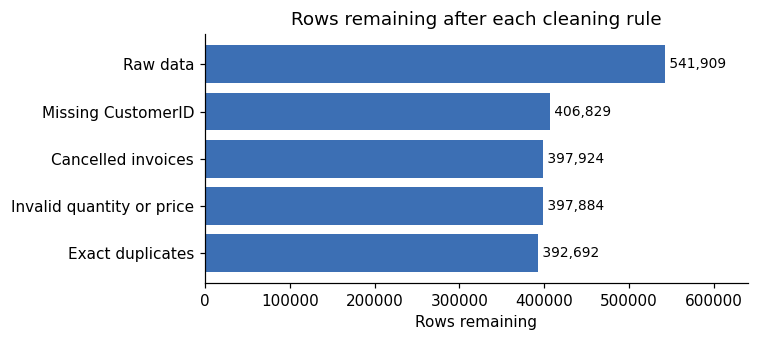

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(clean_log["Step"][::-1], clean_log["Rows remaining"][::-1], color="#3c6fb4")
for i, v in enumerate(clean_log["Rows remaining"][::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_xlabel("Rows remaining"); ax.set_xlim(0, 640_000); ax.set_title("Rows remaining after each cleaning rule")
savefig("f_cleaning_funnel")

## Part 2 — Extended RFM features
For each customer: **R** days since last purchase (reference = day after the last transaction),
**F** distinct invoices, **M** total spend, **T** mean days between distinct purchase days (0 if one day),
**D** distinct products. Then `log(1+x)` and standardisation.

In [6]:
def build_features(t, ref):
    g = t.groupby("CustomerID")
    f = pd.DataFrame({
        "Recency": (ref - g["InvoiceDate"].max()).dt.days,
        "Frequency": g["InvoiceNo"].nunique(),
        "Monetary": g["Amount"].sum(),
        "Basket_Depth": g["StockCode"].nunique(),
    })
    days = t.assign(Day=t["InvoiceDate"].dt.normalize())[["CustomerID", "Day"]].drop_duplicates().sort_values(["CustomerID", "Day"])
    f["InterPurchase_Time"] = days.groupby("CustomerID")["Day"].agg(lambda s: s.diff().dt.days.mean()).fillna(0.0)
    return f[FEATS]


def scale(f, cols=FEATS):
    return StandardScaler().fit_transform(np.log1p(f[cols]))


def hopkins(X, frac=0.1, seed=SEED):
    """Hopkins statistic: ~0.5 for uniform data, close to 1 for clustered data."""
    rng = np.random.default_rng(seed)
    m = int(frac * len(X))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    w = nn.kneighbors(X[rng.choice(len(X), m, replace=False)])[0][:, 1]
    u = nn.kneighbors(rng.uniform(X.min(0), X.max(0), (m, X.shape[1])), n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())


REF = tx["InvoiceDate"].max() + pd.Timedelta(days=1)
feat = build_features(tx, REF)
X = scale(feat)
N = len(feat)
assert N == 4_338

desc = feat.describe().T[["mean", "std", "min", "50%", "max"]]
desc["skewness"] = feat.apply(skew)
desc = desc.rename(columns={"mean": "Mean", "std": "Std", "min": "Min", "50%": "Median", "max": "Max", "skewness": "Skewness"}).round(2)
save_table(desc.rename_axis("Feature"), "t_descriptive", index=True)

skew_tbl = pd.DataFrame({"Raw skewness": feat.apply(skew), "After log1p": np.log1p(feat).apply(skew),
                         "After scaling": pd.DataFrame(X, columns=FEATS).apply(skew).values}, index=FEATS).round(3)
save_table(skew_tbl.rename_axis("Feature"), "t_skewness", index=True)

single = int((feat["Frequency"] == 1).sum())
top10 = feat["Monetary"].sort_values(ascending=False)
RESULTS.update(customers=N, single_buyers=single, single_pct=round(100 * single / N, 2),
               top10_revenue_pct=round(100 * top10.head(int(0.1 * N)).sum() / top10.sum(), 2),
               hopkins=round(hopkins(X), 3),
               monetary_skew_raw=round(skew(feat["Monetary"]), 2), monetary_skew_log=round(skew(np.log1p(feat["Monetary"])), 3))
print(RESULTS)
desc

{'raw_rows': 541909, 'clean_rows': 392692, 'clean_share_pct': 72.46, 'missing_id_pct': np.float64(24.93), 'customers': 4338, 'single_buyers': 1493, 'single_pct': 34.42, 'top10_revenue_pct': np.float64(61.41), 'hopkins': np.float64(0.89), 'monetary_skew_raw': np.float64(19.33), 'monetary_skew_log': np.float64(0.396)}


,Mean,Std,Min,Median,Max,Skewness
Recency,92.54,100.01,1.00,51.00,374.00,1.25
Frequency,4.27,7.70,1.00,2.00,209.00,12.06
Monetary,2048.69,8985.23,3.75,668.57,280206.02,19.33
InterPurchase_Time,50.44,65.24,0.00,31.00,366.00,1.99
Basket_Depth,61.50,85.37,1.00,35.00,1787.00,6.92


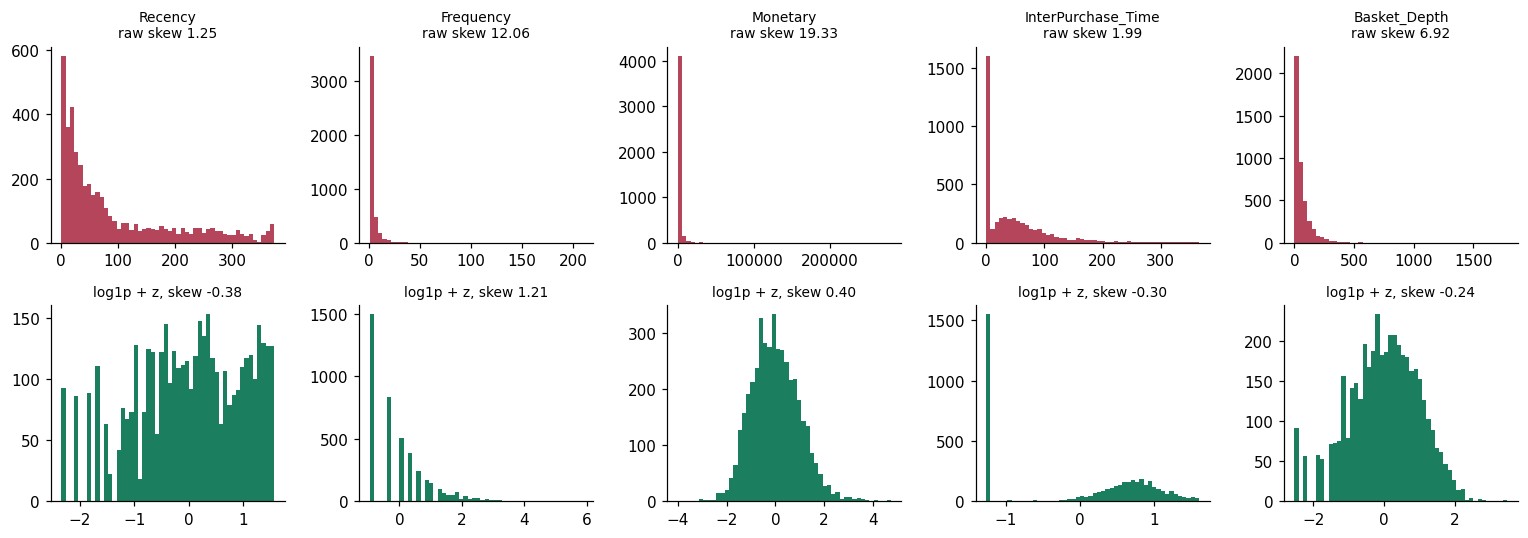

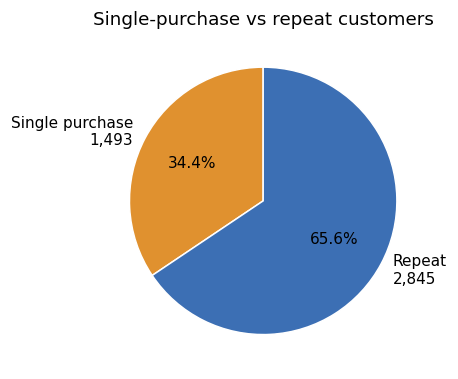

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for i, c in enumerate(FEATS):
    axes[0, i].hist(feat[c], bins=50, color="#b5455b"); axes[0, i].set_title(f"{c}\nraw skew {skew(feat[c]):.2f}", fontsize=9)
    axes[1, i].hist(X[:, i], bins=50, color="#1b7f5f"); axes[1, i].set_title(f"log1p + z, skew {skew(X[:, i]):.2f}", fontsize=9)
savefig("f_skewness")

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.pie([single, N - single], labels=[f"Single purchase\n{single:,}", f"Repeat\n{N - single:,}"], autopct="%1.1f%%",
       colors=["#e0912f", "#3c6fb4"], startangle=90, wedgeprops={"edgecolor": "white"})
ax.set_title("Single-purchase vs repeat customers")
savefig("f_single_vs_repeat")

## Part 3 — Choosing the number of clusters

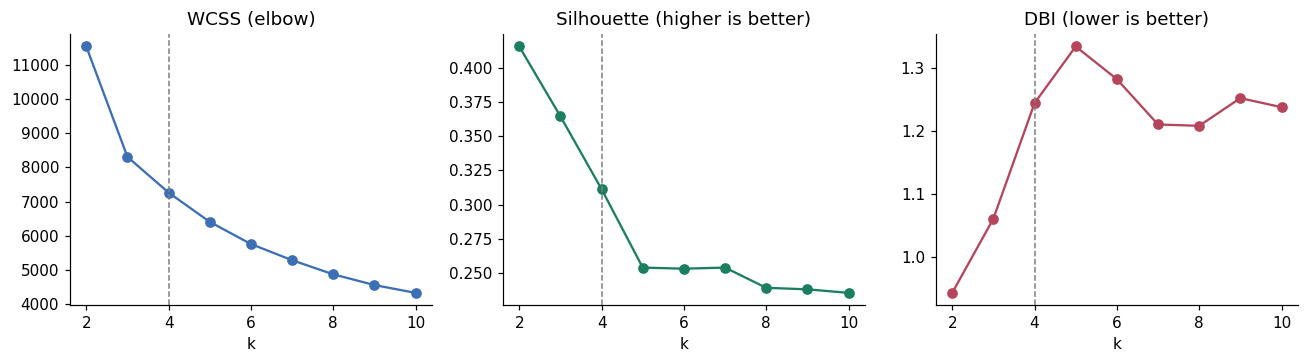

,k,WCSS,Silhouette,DBI,CH
0,2,11535.1,0.4157,0.9440,3817.2
1,3,8308.1,0.3646,1.0613,3491.2
2,4,7264.4,0.3113,1.2442,2868.8
3,5,6408.7,0.2539,1.3338,2583.0
4,6,5762.2,0.2531,1.2821,2394.9
5,7,5288.9,0.2539,1.2104,2238.4
6,8,4876.8,0.2391,1.2083,2132.6
7,9,4563.0,0.2380,1.2521,2031.2
8,10,4334.6,0.2354,1.2378,1925.4


In [8]:
def kmeans(k, seed=SEED):
    return KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=seed)


rows = []
for k in range(2, 11):
    km = kmeans(k).fit(X)
    rows.append(dict(k=k, WCSS=round(km.inertia_, 1), Silhouette=round(silhouette_score(X, km.labels_), 4),
                     DBI=round(davies_bouldin_score(X, km.labels_), 4), CH=round(calinski_harabasz_score(X, km.labels_), 1)))
k_tbl = save_table(pd.DataFrame(rows), "t_k_selection")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, c, sub in zip(axes, ["WCSS", "Silhouette", "DBI"], ["#3c6fb4", "#1b7f5f", "#b5455b"], ["elbow", "higher is better", "lower is better"]):
    ax.plot(k_tbl["k"], k_tbl[col], "o-", color=c); ax.axvline(4, ls="--", color="grey", lw=1)
    ax.set_xlabel("k"); ax.set_title(f"{col} ({sub})")
savefig("f_k_selection")
k_tbl

## Part 4 — The four segments (K-Means, k = 4)
Clusters are ranked by mean spend and named from Champions down to Hibernating.

In [9]:
def rank_by_spend(labels, f):
    """Relabel clusters 0..k-1 by descending mean Monetary value, so label 0 is always the top spenders."""
    order = pd.Series(f["Monetary"].values).groupby(labels).mean().sort_values(ascending=False).index
    return pd.Series(labels).map({old: new for new, old in enumerate(order)}).values


km4 = kmeans(4).fit(X)
lab = rank_by_spend(km4.labels_, feat)
feat["Segment"] = [SEG_NAMES[i] for i in lab]
RESULTS["silhouette_k4"] = round(silhouette_score(X, lab), 4)

prof = feat.groupby("Segment", sort=False)[FEATS].mean().reindex(SEG_NAMES)
prof.insert(0, "Share (%)", (feat["Segment"].value_counts(normalize=True) * 100).reindex(SEG_NAMES))
prof.insert(0, "Customers", feat["Segment"].value_counts().reindex(SEG_NAMES))
prof["Revenue (%)"] = (feat.groupby("Segment")["Monetary"].sum() / feat["Monetary"].sum() * 100).reindex(SEG_NAMES)
prof = prof.round(2)
save_table(prof.rename(columns={"Recency": "R (days)", "Frequency": "F", "Monetary": "M", "InterPurchase_Time": "T (days)", "Basket_Depth": "D"}), "t_segment_means", index=True)
med = feat.groupby("Segment")[FEATS].median().reindex(SEG_NAMES).round(2)
save_table(med.rename(columns={"InterPurchase_Time": "T", "Basket_Depth": "D"}), "t_segment_medians", index=True)
RESULTS["segments"] = {s: {"n": int(prof.loc[s, "Customers"]), "share": float(prof.loc[s, "Share (%)"]), "revenue": float(prof.loc[s, "Revenue (%)"]),
                           **{c: float(prof.loc[s, c]) for c in FEATS}} for s in SEG_NAMES}
prof

,Customers,Share (%),Recency,Frequency,Monetary,InterPurchase_Time,Basket_Depth,Revenue (%)
Segment,,,,,,,,
Champions (VIP Loyalists),515,11.87,12.38,16.51,10253.30,32.55,184.04,59.42
Loyal & Promising Regulars,1180,27.20,33.21,4.66,1795.53,73.66,87.56,23.84
High-Potential / At-Risk,1071,24.69,102.95,2.68,763.65,107.31,32.34,9.20
Hibernating / Lost,1572,36.24,156.24,1.06,426.31,0.13,21.67,7.54


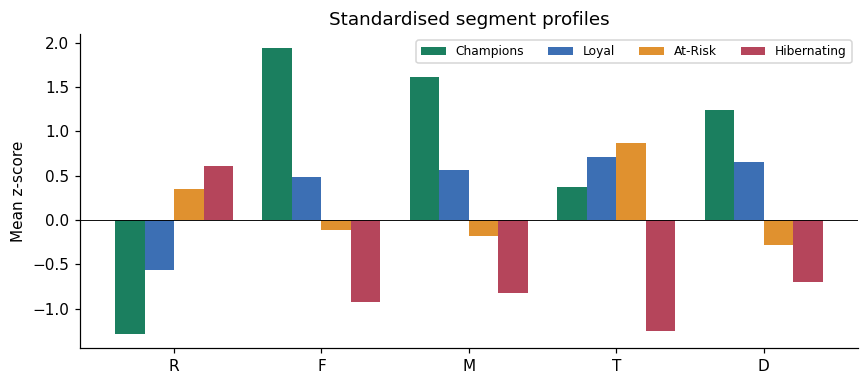

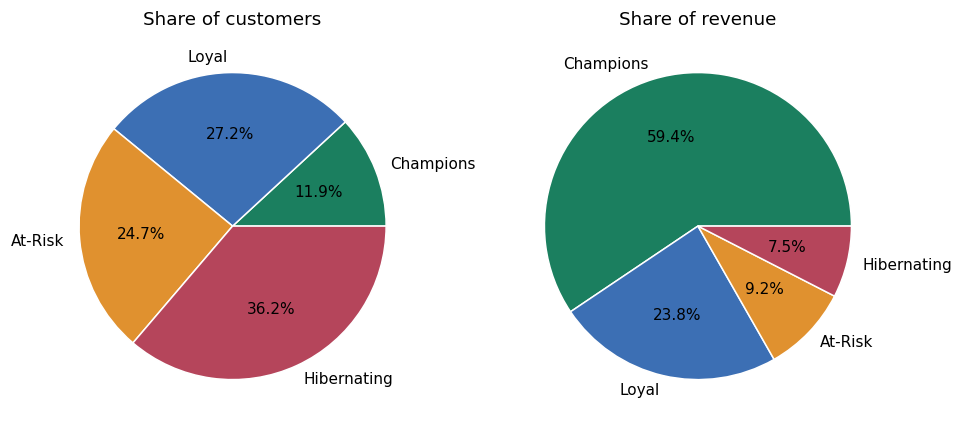

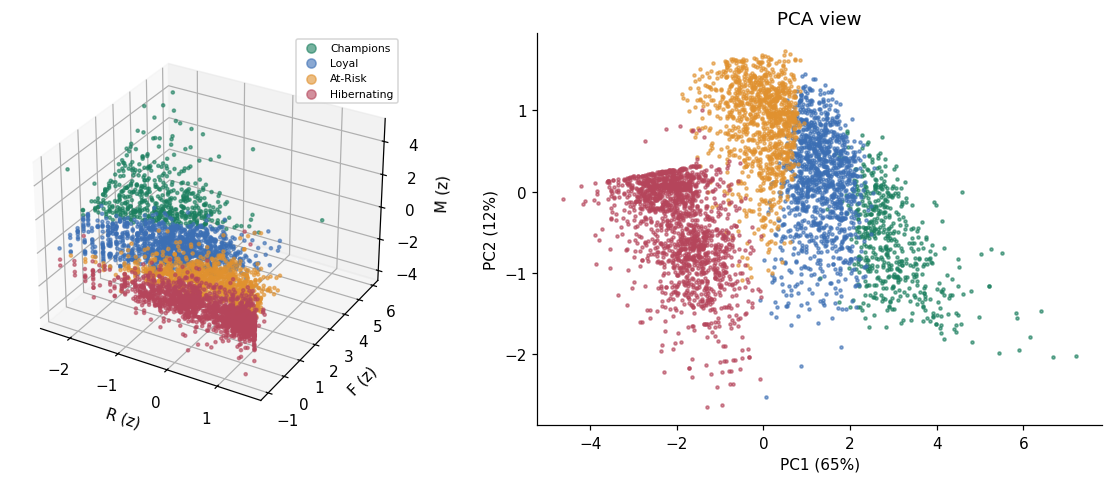

In [10]:
z = pd.DataFrame(X, columns=FEATS).groupby(lab).mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.2
for i in range(4):
    ax.bar(np.arange(5) + (i - 1.5) * w, z.loc[i], w, label=SHORT[i], color=COLORS[i])
ax.set_xticks(range(5), ["R", "F", "M", "T", "D"]); ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Mean z-score"); ax.legend(ncol=4, fontsize=8); ax.set_title("Standardised segment profiles")
savefig("f_segment_profiles")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].pie(prof["Customers"], labels=SHORT, colors=COLORS, autopct="%1.1f%%", wedgeprops={"edgecolor": "white"}); axes[0].set_title("Share of customers")
axes[1].pie(prof["Revenue (%)"], labels=SHORT, colors=COLORS, autopct="%1.1f%%", wedgeprops={"edgecolor": "white"}); axes[1].set_title("Share of revenue")
savefig("f_segment_share")

fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for i in range(4):
    m = lab == i
    ax.scatter(X[m, 0], X[m, 1], X[m, 2], s=4, color=COLORS[i], label=SHORT[i], alpha=0.6)
ax.set_xlabel("R (z)"); ax.set_ylabel("F (z)"); ax.set_zlabel("M (z)"); ax.legend(fontsize=7, markerscale=3)
ax2 = fig.add_subplot(1, 2, 2)
P = PCA(2, random_state=SEED).fit(X)
Z2 = P.transform(X)
for i in range(4):
    ax2.scatter(Z2[lab == i, 0], Z2[lab == i, 1], s=4, color=COLORS[i], label=SHORT[i], alpha=0.6)
ax2.set_xlabel(f"PC1 ({P.explained_variance_ratio_[0]:.0%})"); ax2.set_ylabel(f"PC2 ({P.explained_variance_ratio_[1]:.0%})"); ax2.set_title("PCA view")
RESULTS["pca_var_2d"] = round(float(P.explained_variance_ratio_.sum()), 3)
savefig("f_clusters_3d_pca")

### Part 4b — Two-track initial segmentation: early-stage customers get their own segments
Supervisor's requirement: segment new customers and customers with little purchase history separately from the start,
not only guest buyers. **Early-stage** = first order within the last 90 days **or** at most 2 orders.
Their inter-purchase time is almost always 0, so their model uses **Tenure** (days since first order) instead of T.
Established customers keep the five Extended RFM features and four segments. Part 14 tests how reliable these
early-stage segments are and how well they predict future purchases.

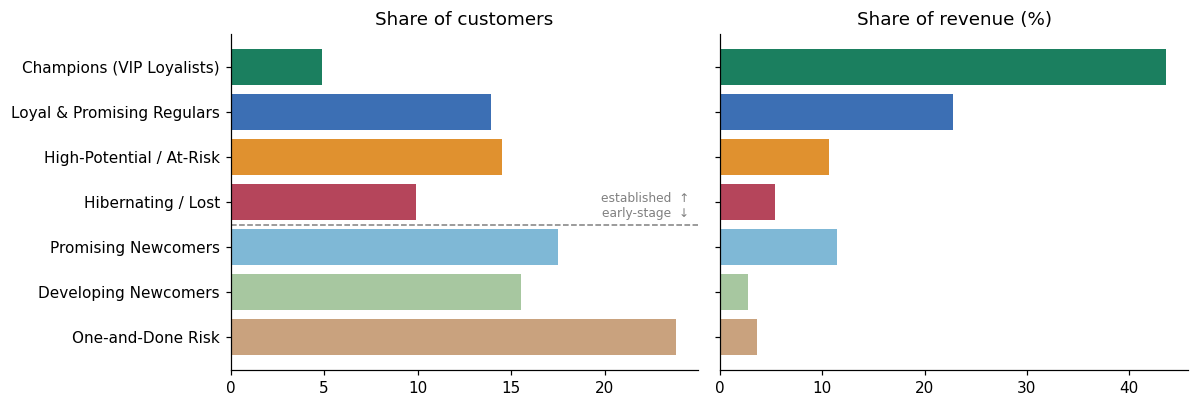

(                                  Track  Customers  Share (%)  Revenue (%)  \
 Segment                                                                      
 Champions (VIP Loyalists)   Established        214        4.9         43.6   
 Loyal & Promising Regulars  Established        604       13.9         22.8   
 High-Potential / At-Risk    Established        628       14.5         10.6   
 Hibernating / Lost          Established        428        9.9          5.4   
 Promising Newcomers         Early-stage        761       17.5         11.4   
 Developing Newcomers        Early-stage        672       15.5          2.7   
 One-and-Done Risk           Early-stage       1031       23.8          3.6   
 
                             Recency  Frequency  Monetary  InterPurchase_Time  \
 Segment                                                                        
 Champions (VIP Loyalists)      10.4       26.2   18122.0                20.3   
 Loyal & Promising Regulars     25.6        

In [11]:
EARLY_FEATS = ["Recency", "Frequency", "Monetary", "Basket_Depth", "Tenure"]
EARLY_NAMES = ["Promising Newcomers", "Developing Newcomers", "One-and-Done Risk"]
TRACK_NAMES = SEG_NAMES + EARLY_NAMES

tenure_all = (REF - tx.groupby("CustomerID")["InvoiceDate"].min()).dt.days.reindex(feat.index)
is_early = ((tenure_all <= 90) | (feat["Frequency"] <= 2)).values
f_est = feat.loc[~is_early, FEATS]
f_new = feat.loc[is_early, FEATS].assign(Tenure=tenure_all[is_early])
X_est0, X_new0 = scale(f_est), scale(f_new, EARLY_FEATS)
lab_est = rank_by_spend(kmeans(4).fit_predict(X_est0), f_est)
lab_new = rank_by_spend(kmeans(3).fit_predict(X_new0), f_new)
seg2 = pd.Series("", index=feat.index)
seg2.loc[f_est.index] = [SEG_NAMES[i] for i in lab_est]
seg2.loc[f_new.index] = [EARLY_NAMES[i] for i in lab_new]
assert (seg2 != "").all()

two = feat[FEATS].assign(Tenure=tenure_all, Segment=seg2, Track=np.where(is_early, "Early-stage", "Established"))
g2 = two.groupby("Segment")
tp = g2[FEATS + ["Tenure"]].mean().reindex(TRACK_NAMES)
tp.insert(0, "Revenue (%)", g2["Monetary"].sum() / feat["Monetary"].sum() * 100)
tp.insert(0, "Share (%)", g2.size() / N * 100)
tp.insert(0, "Customers", g2.size())
tp.insert(0, "Track", g2["Track"].first())
tp = tp.round(1)
save_table(tp.rename(columns={"Recency": "R", "Frequency": "F", "Monetary": "M", "InterPurchase_Time": "T", "Basket_Depth": "D"}).rename_axis("Segment"),
           "t_two_track_segments", index=True)

# Where the single global model put the early-stage customers: they are spread over the ordinary segments.
xt = pd.crosstab(pd.Series(seg2[is_early].values, name="Early-stage segment"),
                 pd.Series([SHORT[i] for i in lab[is_early]], name="Global k=4 segment")).reindex(index=EARLY_NAMES, columns=SHORT, fill_value=0)
save_table(xt, "t_two_track_vs_global", index=True)

track_q = pd.DataFrame([
    {"Track": t, "Customers": len(Xt), "Segments": k, "Silhouette": round(silhouette_score(Xt, lb), 4),
     "DBI": round(davies_bouldin_score(Xt, lb), 4), "Largest segment (%)": round(100 * np.bincount(lb).max() / len(lb), 1)}
    for t, Xt, lb, k in [("Established (5 Extended RFM features)", X_est0, lab_est, 4), ("Early-stage (R, F, M, D, Tenure)", X_new0, lab_new, 3)]])
save_table(track_q, "t_two_track_quality")
RESULTS["two_track"] = {"early_n": int(is_early.sum()), "early_pct": round(100 * is_early.mean(), 1),
                        "early_revenue_pct": round(100 * feat.loc[is_early, "Monetary"].sum() / feat["Monetary"].sum(), 1),
                        "segments": {s: int(tp.loc[s, "Customers"]) for s in TRACK_NAMES},
                        "quality": track_q.to_dict(orient="records")}

TRACK_COLORS = COLORS + ["#7fb8d6", "#a7c7a0", "#c9a27e"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col in zip(axes, ["Share (%)", "Revenue (%)"]):
    ax.barh(TRACK_NAMES[::-1], tp[col][::-1], color=TRACK_COLORS[::-1])
    ax.set_title(f"{col.split(' ')[0]} of customers" if col == "Share (%)" else "Share of revenue (%)")
axes[0].axhline(2.5, color="grey", ls="--", lw=1)
axes[0].text(axes[0].get_xlim()[1] * 0.98, 2.6, "established  ↑\nearly-stage  ↓", ha="right", va="bottom", fontsize=8, color="grey")
savefig("f_two_track_segments")
tp, track_q, xt

## Part 5 — Six-algorithm benchmark with a validity check
A clustering is a **valid segmentation** only if it has ≥ 2 clusters and every cluster holds between 2% and 80% of customers.

In [12]:
def validity(labels):
    core = labels[labels >= 0]
    sizes = pd.Series(core).value_counts(normalize=True) * 100
    noise = 100 * (labels < 0).mean()
    ok = len(sizes) >= 2 and sizes.min() >= 2 and sizes.max() <= 80
    return noise, sizes.min(), sizes.max(), bool(ok)


algos = {
    "K-Means": lambda: kmeans(4).fit_predict(X),
    "Ward": lambda: AgglomerativeClustering(4, linkage="ward").fit_predict(X),
    "Average linkage": lambda: AgglomerativeClustering(4, linkage="average").fit_predict(X),
    "Complete linkage": lambda: AgglomerativeClustering(4, linkage="complete").fit_predict(X),
    "Gaussian mixture": lambda: GaussianMixture(4, random_state=SEED).fit_predict(X),
    "DBSCAN (0.8, 10)": lambda: DBSCAN(eps=0.8, min_samples=10).fit_predict(X),
    "HDBSCAN (min size 50)": lambda: HDBSCAN(min_cluster_size=50).fit_predict(X),
    "BIRCH": lambda: Birch(n_clusters=4).fit_predict(X),
}
bench, valid_rows, bench_labels = [], [], {}
for name, fn in algos.items():
    t0 = time.perf_counter(); lb = fn(); dt = time.perf_counter() - t0
    bench_labels[name] = lb
    core = lb >= 0
    nk = len(set(lb[core]))
    s = (silhouette_score(X[core], lb[core]), davies_bouldin_score(X[core], lb[core]), calinski_harabasz_score(X[core], lb[core])) if nk > 1 else (np.nan,) * 3
    bench.append({"Algorithm": name, "Clusters": nk, "Silhouette": round(s[0], 4), "DBI": round(s[1], 4), "CH": round(s[2], 1),
                  "Time (s)": round(dt, 3), "ARI vs K-Means": round(adjusted_rand_score(bench_labels["K-Means"], lb), 4)})
    noise, smin, smax, ok = validity(lb)
    valid_rows.append({"Algorithm": name, "Noise (%)": round(noise, 2), "Smallest (%)": round(smin, 2), "Largest (%)": round(smax, 2), "Valid": ok})
bench_tbl = save_table(pd.DataFrame(bench), "t_benchmark")
valid_tbl = save_table(pd.DataFrame(valid_rows), "t_validity")

# DBSCAN grid: does any setting give 4 balanced clusters?
grid = [(e, m) for e in (0.3, 0.5, 0.8, 1.0, 1.2, 1.5) for m in (5, 10, 20)]
RESULTS["dbscan_grid_valid_4"] = int(sum(len(set(l[l >= 0])) == 4 and validity(l)[3] for l in (DBSCAN(eps=e, min_samples=m).fit_predict(X) for e, m in grid)))
RESULTS["dbscan_grid_size"] = len(grid)
pd.concat([bench_tbl, valid_tbl.drop(columns="Algorithm")], axis=1)

,Algorithm,Clusters,Silhouette,DBI,CH,Time (s),ARI vs K-Means,Noise (%),Smallest (%),Largest (%),Valid
0,K-Means,4,0.3113,1.2442,2868.8,0.060,1.0000,0.00,11.87,36.24,True
1,Ward,4,0.2949,1.3103,2708.7,1.694,0.8102,0.00,11.96,36.01,True
2,Average linkage,4,0.3411,0.8442,52.0,2.229,0.0039,0.00,0.02,99.45,False
3,Complete linkage,4,0.1002,0.9935,533.7,1.674,0.0835,0.00,0.14,88.68,False
4,Gaussian mixture,4,0.1944,2.0743,1870.1,0.322,0.5661,0.00,19.13,34.42,True
5,"DBSCAN (0.8, 10)",1,NaN,NaN,NaN,0.614,0.0097,3.07,100.00,100.00,False
6,HDBSCAN (min size 50),2,0.5027,0.7662,4547.3,0.604,0.4386,20.61,40.04,59.96,True
7,BIRCH,4,0.2165,1.3442,1858.6,0.219,0.3511,0.00,3.94,49.08,True


## Part 6 — Segment quality, stability, generalisation and seed robustness

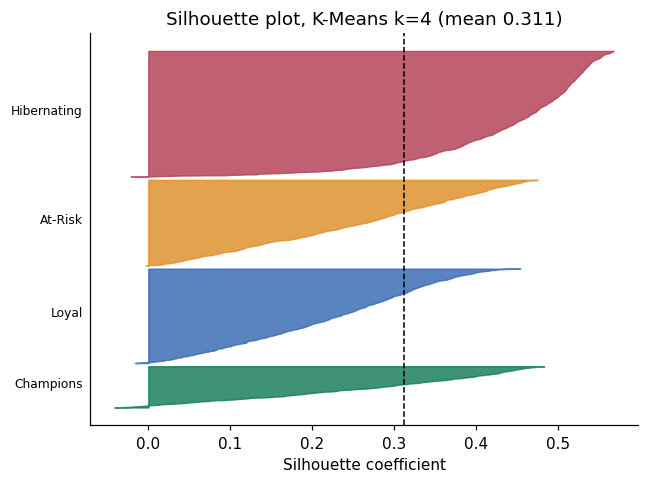

,Segment,Size,Mean silhouette,Minimum,Negative (%)
0,Champions (VIP Loyalists),515,0.2607,-0.0413,5.24
1,Loyal & Promising Regulars,1180,0.2222,-0.0161,0.93
2,High-Potential / At-Risk,1071,0.2508,-0.0029,0.37
3,Hibernating / Lost,1572,0.4359,-0.0215,0.25


In [13]:
sil = silhouette_samples(X, lab)
seg_sil = pd.DataFrame({"Segment": SEG_NAMES, "Size": [int((lab == i).sum()) for i in range(4)],
                        "Mean silhouette": [round(sil[lab == i].mean(), 4) for i in range(4)],
                        "Minimum": [round(sil[lab == i].min(), 4) for i in range(4)],
                        "Negative (%)": [round(100 * (sil[lab == i] < 0).mean(), 2) for i in range(4)]})
save_table(seg_sil, "t_segment_silhouette")
RESULTS["negative_sil_pct"] = round(100 * (sil < 0).mean(), 3)

fig, ax = plt.subplots(figsize=(6, 4.5))
y0 = 0
for i in range(4):
    v = np.sort(sil[lab == i])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORS[i], alpha=0.85)
    ax.text(-0.08, y0 + len(v) / 2, SHORT[i], fontsize=8, ha="right")
    y0 += len(v) + 40
ax.axvline(sil.mean(), ls="--", color="black", lw=1); ax.set_yticks([]); ax.set_xlabel("Silhouette coefficient")
ax.set_title(f"Silhouette plot, K-Means k=4 (mean {sil.mean():.3f})")
savefig("f_silhouette_plot")
seg_sil

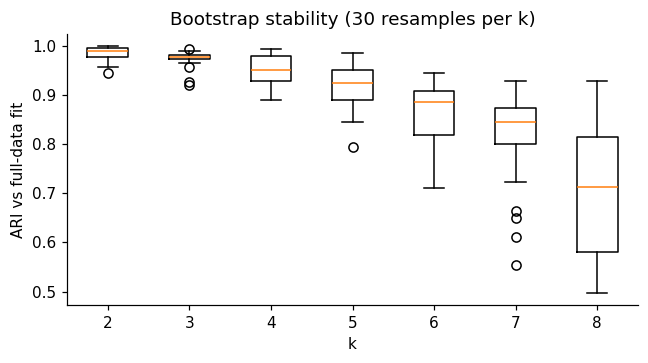

{'stability_k4_mean': np.float64(0.9524), 'sil_train': 0.3098, 'sil_test': 0.3139, 'seed_sil_min': np.float64(0.3113), 'seed_sil_max': np.float64(0.3113), 'seed_ari_min': np.float64(0.9994)}


,k,Mean ARI,Std ARI,Min ARI,Max ARI
0,2,0.9843,0.0152,0.9445,0.9991
1,3,0.9740,0.0154,0.9207,0.9946
2,4,0.9524,0.0303,0.8897,0.9941
3,5,0.9182,0.0437,0.7946,0.9853
4,6,0.8625,0.0636,0.7100,0.9455
5,7,0.8206,0.0929,0.5544,0.9291
6,8,0.7018,0.1365,0.4974,0.9280


In [14]:
def bootstrap_ari(Xm, k, B=30, seed=SEED):
    """Fit K-Means on B bootstrap resamples, label everyone, compare with the full-data fit."""
    rng = np.random.default_rng(seed)
    ref = kmeans(k).fit(Xm).labels_
    return np.array([adjusted_rand_score(ref, kmeans(k).fit(Xm[rng.integers(0, len(Xm), len(Xm))]).predict(Xm)) for _ in range(B)])


stab = {k: bootstrap_ari(X, k) for k in range(2, 9)}
stab_tbl = save_table(pd.DataFrame([{"k": k, "Mean ARI": round(a.mean(), 4), "Std ARI": round(a.std(), 4), "Min ARI": round(a.min(), 4), "Max ARI": round(a.max(), 4)} for k, a in stab.items()]), "t_stability")
RESULTS["stability_k4_mean"], RESULTS["stability_k4_min"] = round(stab[4].mean(), 4), round(stab[4].min(), 4)

Xtr, Xte = train_test_split(X, test_size=0.2, random_state=SEED)
kmg = kmeans(4).fit(Xtr)
RESULTS["sil_train"], RESULTS["sil_test"] = round(silhouette_score(Xtr, kmg.labels_), 4), round(silhouette_score(Xte, kmg.predict(Xte)), 4)

# Seed robustness: does the partition depend on the random seed?
seed_runs = [kmeans(4, s).fit(X) for s in range(20)]
seed_sil = np.array([silhouette_score(X, m.labels_) for m in seed_runs])
seed_ari = np.array([adjusted_rand_score(lab, m.labels_) for m in seed_runs])
RESULTS["seed_sil_min"], RESULTS["seed_sil_max"] = round(seed_sil.min(), 4), round(seed_sil.max(), 4)
RESULTS["seed_ari_min"] = round(seed_ari.min(), 4)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.boxplot([stab[k] for k in stab], tick_labels=list(stab)); ax.set_xlabel("k"); ax.set_ylabel("ARI vs full-data fit")
ax.set_title("Bootstrap stability (30 resamples per k)")
savefig("f_stability")
print({k: RESULTS[k] for k in ["stability_k4_mean", "sil_train", "sil_test", "seed_sil_min", "seed_sil_max", "seed_ari_min"]})
stab_tbl

## Part 7 — Out-of-sample predictive validation
Internal indices judge geometry, not usefulness. Segments are built **only from data before the cutoff**
and judged on what customers did **after** it: did they buy again (AUC), and how much did they spend
(Spearman ρ, adjusted R² of log spend). Every segmentation is turned into a predictor the same way:
one-hot segment → logistic / linear regression, out-of-fold predictions from 5-fold CV.

In [15]:
CUTOFF = pd.Timestamp("2011-09-01")


def oos_setup(cutoff, horizon_days=None):
    pre = tx[tx["InvoiceDate"] < cutoff]
    end = cutoff + pd.Timedelta(days=horizon_days) if horizon_days else tx["InvoiceDate"].max() + pd.Timedelta(seconds=1)
    post = tx[(tx["InvoiceDate"] >= cutoff) & (tx["InvoiceDate"] < end)]
    f = build_features(pre, cutoff)
    spend = post.groupby("CustomerID")["Amount"].sum().reindex(f.index).fillna(0.0)
    return pre, f, (spend > 0).astype(int).values, spend.values


def quintile_rfm(f):
    q = lambda s, asc: pd.qcut(s.rank(method="first", ascending=asc), 5, labels=False) + 1
    score = q(f["Recency"], False) + q(f["Frequency"], True) + q(f["Monetary"], True)
    return pd.qcut(score.rank(method="first"), 4, labels=False).values


def evaluate(labels, y, spend):
    """Out-of-fold repurchase AUC, spend Spearman, and adjusted R² of log spend for a segmentation."""
    Z = pd.get_dummies(pd.Series(labels).astype(str)).values.astype(float)
    p = cross_val_predict(LogisticRegression(max_iter=2000), Z, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    ls = np.log1p(spend)
    ps = cross_val_predict(LinearRegression(), Z, ls, cv=KFold(5, shuffle=True, random_state=SEED))
    n, k = len(y), Z.shape[1] - 1
    r2 = LinearRegression().fit(Z, ls).score(Z, ls)
    adj = 1 - (1 - r2) * (n - 1) / (n - k - 1) if k > 0 else 0.0
    return dict(auc=roc_auc_score(y, p), rho=spearmanr(ps, spend).statistic, adj_r2=adj), p


def km_labels(f, k, cols=FEATS):
    return rank_by_spend(kmeans(k).fit(scale(f, cols)).labels_, f)


pre, fpre, y, spend = oos_setup(CUTOFF)
RESULTS["oos_customers"], RESULTS["oos_repurchase_pct"] = len(fpre), round(100 * y.mean(), 1)
RFM3 = ["Recency", "Frequency", "Monetary"]
methods = {
    "No segmentation": np.zeros(len(fpre), int),
    "Single guest rule (F=1 vs F>1)": (fpre["Frequency"] > 1).astype(int).values,
    "Classic quintile RFM score (4 groups)": quintile_rfm(fpre),
    **{f"KM Extended RFM (k={k})": km_labels(fpre, k) for k in (2, 3, 4, 5, 6, 8)},
    "KM plain RFM (k=4)": km_labels(fpre, 4, RFM3),
    "KM RFM+T (k=4)": km_labels(fpre, 4, RFM3 + ["InterPurchase_Time"]),
    "KM RFM+Depth (k=4)": km_labels(fpre, 4, RFM3 + ["Basket_Depth"]),
}
oos_rows, oof = [], {}
for name, lb in methods.items():
    m, oof[name] = evaluate(lb, y, spend)
    oos_rows.append({"Method": name, "Segments": len(set(lb)), "Repurchase AUC": round(m["auc"], 3), "Spend Spearman": round(m["rho"], 3), "Adj. R2 (log spend)": round(m["adj_r2"], 3)})
oos_tbl = save_table(pd.DataFrame(oos_rows), "t_oos")

# Supervised reference: logistic / linear regression directly on the 5 scaled features (an upper bound for segment-based predictors).
Xp = scale(fpre)
sup_p = cross_val_predict(LogisticRegression(max_iter=2000), Xp, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
sup_s = cross_val_predict(LinearRegression(), Xp, np.log1p(spend), cv=KFold(5, shuffle=True, random_state=SEED))
RESULTS["supervised_auc"], RESULTS["supervised_rho"] = round(roc_auc_score(y, sup_p), 3), round(spearmanr(sup_s, spend).statistic, 3)
oos_tbl

,Method,Segments,Repurchase AUC,Spend Spearman,Adj. R2 (log spend)
0,No segmentation,1,0.500,-0.047,0.000
1,Single guest rule (F=1 vs F>1),2,0.657,0.289,0.126
2,Classic quintile RFM score (4 groups),4,0.715,0.457,0.217
3,KM Extended RFM (k=2),2,0.679,0.343,0.166
4,KM Extended RFM (k=3),3,0.704,0.434,0.217
5,KM Extended RFM (k=4),4,0.712,0.452,0.220
6,KM Extended RFM (k=5),5,0.723,0.489,0.248
7,KM Extended RFM (k=6),6,0.727,0.499,0.251
8,KM Extended RFM (k=8),8,0.731,0.501,0.254
9,KM plain RFM (k=4),4,0.704,0.455,0.223


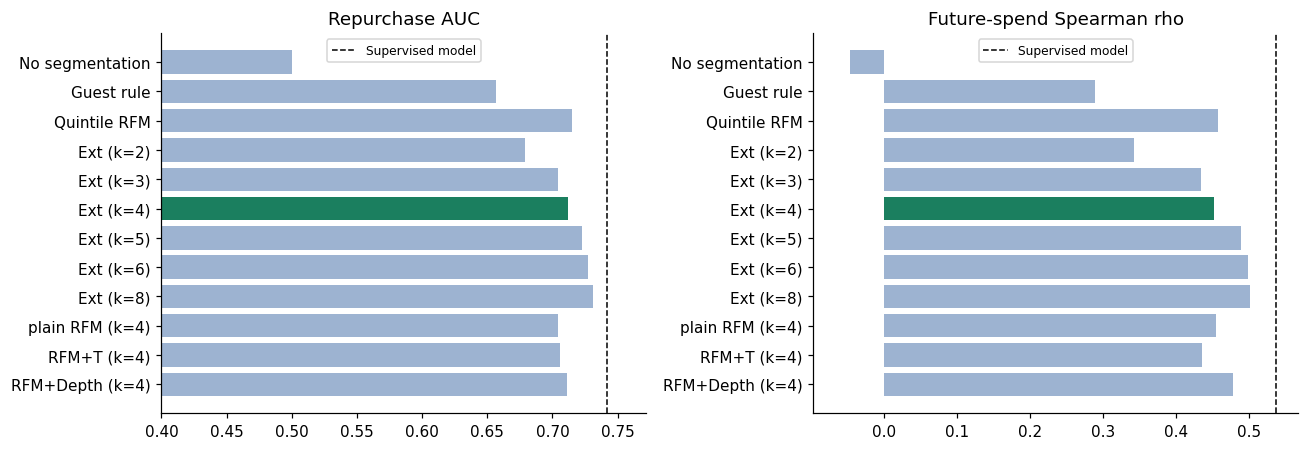

,Comparison,Mean,95% CI low,95% CI high
0,k=4 minus k=2,0.034,0.022,0.047
1,Extended k=4 minus quintile RFM,-0.003,-0.015,0.009
2,Extended k=4 minus plain RFM k=4,0.010,-0.003,0.026
3,k=4 minus single guest rule,0.055,0.040,0.068


In [16]:
def boot_diff(a, b, B=200, seed=SEED):
    """Bootstrap the difference in AUC between two out-of-fold predictors (same customers resampled for both)."""
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        d.append(roc_auc_score(y[i], oof[a][i]) - roc_auc_score(y[i], oof[b][i]))
    d = np.array(d)
    return round(d.mean(), 3), round(np.percentile(d, 2.5), 3), round(np.percentile(d, 97.5), 3)


comparisons = [("k=4 minus k=2", "KM Extended RFM (k=4)", "KM Extended RFM (k=2)"),
               ("Extended k=4 minus quintile RFM", "KM Extended RFM (k=4)", "Classic quintile RFM score (4 groups)"),
               ("Extended k=4 minus plain RFM k=4", "KM Extended RFM (k=4)", "KM plain RFM (k=4)"),
               ("k=4 minus single guest rule", "KM Extended RFM (k=4)", "Single guest rule (F=1 vs F>1)")]
ci_tbl = save_table(pd.DataFrame([dict(zip(["Comparison", "Mean", "95% CI low", "95% CI high"], (lbl, *boot_diff(a, b)))) for lbl, a, b in comparisons]), "t_oos_ci")

# What each segment did after the cutoff.
lab_pre = methods["KM Extended RFM (k=4)"]
after = pd.DataFrame({"Segment": [SHORT[i] for i in lab_pre], "y": y, "spend": spend})
g = after.groupby("Segment")
seg_after = pd.DataFrame({"Customers": g.size(), "Bought again (%)": (g["y"].mean() * 100).round(1),
                          "Future spend per customer": g["spend"].mean().round(0),
                          "Share of future revenue (%)": (g["spend"].sum() / spend.sum() * 100).round(1)}).reindex(SHORT)
save_table(seg_after.rename_axis("Segment"), "t_oos_segments", index=True)
hib = after[after["Segment"] == "Hibernating"]["spend"].sort_values(ascending=False)
RESULTS["hibernating_top5_future_share"] = round(100 * hib.head(5).sum() / max(hib.sum(), 1e-9), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
short_names = [r["Method"].replace("KM Extended RFM", "Ext").replace("Classic quintile RFM score (4 groups)", "Quintile RFM").replace("Single guest rule (F=1 vs F>1)", "Guest rule").replace("KM ", "") for r in oos_rows]
for ax, col, ref, title in [(axes[0], "Repurchase AUC", RESULTS["supervised_auc"], "Repurchase AUC"), (axes[1], "Spend Spearman", RESULTS["supervised_rho"], "Future-spend Spearman rho")]:
    vals = oos_tbl[col].values
    ax.barh(short_names[::-1], vals[::-1], color=["#1b7f5f" if n == "Ext (k=4)" else "#9db3d1" for n in short_names[::-1]])
    ax.axvline(ref, ls="--", color="black", lw=1, label="Supervised model")
    ax.set_title(title); ax.legend(fontsize=8)
    lo = 0.4 if col.startswith("Rep") else min(0, vals.min() - 0.05)
    ax.set_xlim(lo, max(vals.max(), ref) + 0.03)
savefig("f_oos")
ci_tbl

## Part 8 — Feature ablation: does Extended RFM change the segments?

In [17]:
lab_plain = methods["KM plain RFM (k=4)"]
RESULTS["moved_vs_plain_pct"] = round(100 * (lab_pre != lab_plain).mean(), 1)
RESULTS["ari_ext_vs_plain"] = round(adjusted_rand_score(lab_pre, lab_plain), 4)
RESULTS["stab_pre_ext"] = round(bootstrap_ari(scale(fpre), 4).mean(), 4)
RESULTS["stab_pre_plain"] = round(bootstrap_ari(scale(fpre, RFM3), 4).mean(), 4)
print({k: RESULTS[k] for k in ["moved_vs_plain_pct", "ari_ext_vs_plain", "stab_pre_ext", "stab_pre_plain"]})

{'moved_vs_plain_pct': np.float64(39.3), 'ari_ext_vs_plain': 0.3861, 'stab_pre_ext': np.float64(0.9145), 'stab_pre_plain': np.float64(0.9054)}


## Part 9 — New: robustness across five cutoff dates
The pre-defense used one cutoff (1 Sep 2011) whose holdout includes the holiday peak. Here every cutoff
uses the **same 90-day outcome window**, and the earlier cutoffs exclude the holiday season entirely.

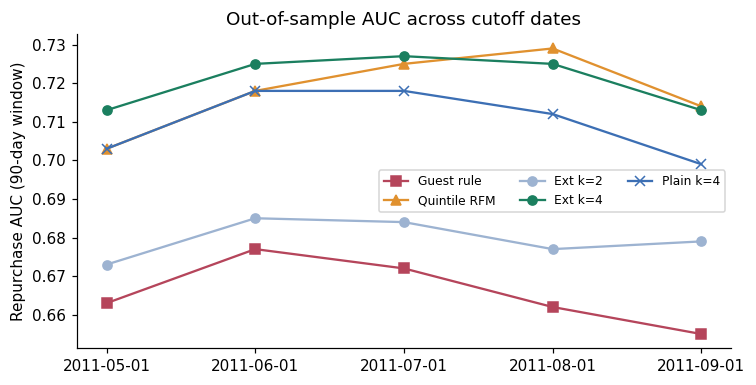

,Cutoff,Customers,Repurchase (%),Guest rule,Quintile RFM,Ext k=2,Ext k=4,Plain k=4
0,2011-05-01,2434,53.9,0.663,0.703,0.673,0.713,0.703
1,2011-06-01,2718,49.3,0.677,0.718,0.685,0.725,0.718
2,2011-07-01,2960,49.5,0.672,0.725,0.684,0.727,0.718
3,2011-08-01,3148,51.9,0.662,0.729,0.677,0.725,0.712
4,2011-09-01,3317,56.2,0.655,0.714,0.679,0.713,0.699


In [18]:
cut_rows = []
for c in ["2011-05-01", "2011-06-01", "2011-07-01", "2011-08-01", "2011-09-01"]:
    _, fc, yc, sc = oos_setup(pd.Timestamp(c), horizon_days=90)
    row = {"Cutoff": c, "Customers": len(fc), "Repurchase (%)": round(100 * yc.mean(), 1)}
    for name, lb in [("Guest rule", (fc["Frequency"] > 1).astype(int).values), ("Quintile RFM", quintile_rfm(fc)),
                     ("Ext k=2", km_labels(fc, 2)), ("Ext k=4", km_labels(fc, 4)), ("Plain k=4", km_labels(fc, 4, RFM3))]:
        row[name] = round(evaluate(lb, yc, sc)[0]["auc"], 3)
    cut_rows.append(row)
cut_tbl = save_table(pd.DataFrame(cut_rows), "t_cutoffs")
RESULTS["cutoff_k4_beats_k2"] = int((cut_tbl["Ext k=4"] > cut_tbl["Ext k=2"]).sum())
RESULTS["cutoff_k4_beats_guest"] = int((cut_tbl["Ext k=4"] > cut_tbl["Guest rule"]).sum())
RESULTS["cutoff_k4_mean"] = round(cut_tbl["Ext k=4"].mean(), 3)
RESULTS["cutoff_k4_vs_plain_mean_diff"] = round((cut_tbl["Ext k=4"] - cut_tbl["Plain k=4"]).mean(), 3)
RESULTS["cutoff_k4_vs_quintile_mean_diff"] = round((cut_tbl["Ext k=4"] - cut_tbl["Quintile RFM"]).mean(), 3)

fig, ax = plt.subplots(figsize=(7, 3.6))
for col, c, mk in [("Guest rule", "#b5455b", "s"), ("Quintile RFM", "#e0912f", "^"), ("Ext k=2", "#9db3d1", "o"), ("Ext k=4", "#1b7f5f", "o"), ("Plain k=4", "#3c6fb4", "x")]:
    ax.plot(cut_tbl["Cutoff"], cut_tbl[col], marker=mk, color=c, label=col)
ax.set_ylabel("Repurchase AUC (90-day window)"); ax.set_title("Out-of-sample AUC across cutoff dates"); ax.legend(fontsize=8, ncol=3)
savefig("f_cutoffs")
cut_tbl

## Part 10 — New: two-stage model (one-time buyers handled separately)
One-time buyers have T = 0 by definition and pull the geometry. Stage 1 puts every F = 1 customer in its
own segment; stage 2 clusters only repeat customers. Compared out of sample against single-stage K-Means.

In [19]:
def two_stage(f, k_repeat):
    lb = np.full(len(f), -1)
    rep = (f["Frequency"] > 1).values
    lb[rep] = km_labels(f[rep], k_repeat)
    lb[~rep] = k_repeat  # one-time buyers form their own segment
    return lb


ts_rows = []
for name, lb in [("Single-stage K-Means (k=4)", methods["KM Extended RFM (k=4)"]),
                 ("Two-stage: one-time + 3 repeat clusters", two_stage(fpre, 3)),
                 ("Two-stage: one-time + 4 repeat clusters", two_stage(fpre, 4))]:
    m, oof[name] = evaluate(lb, y, spend)
    ts_rows.append({"Model": name, "Segments": len(set(lb)), "Repurchase AUC": round(m["auc"], 3), "Spend Spearman": round(m["rho"], 3), "Adj. R2": round(m["adj_r2"], 3)})
ts_tbl = save_table(pd.DataFrame(ts_rows), "t_two_stage")
rep_mask = (feat["Frequency"] > 1).values
Xr = scale(feat[rep_mask])
RESULTS["two_stage_repeat_sil_k3"] = round(silhouette_score(Xr, kmeans(3).fit_predict(Xr)), 4)
RESULTS["two_stage_diff_ci"] = boot_diff("Two-stage: one-time + 3 repeat clusters", "KM Extended RFM (k=4)")
ts_tbl

,Model,Segments,Repurchase AUC,Spend Spearman,Adj. R2
0,Single-stage K-Means (k=4),4,0.712,0.452,0.220
1,Two-stage: one-time + 3 repeat clusters,4,0.708,0.434,0.220
2,Two-stage: one-time + 4 repeat clusters,5,0.719,0.466,0.247


## Part 11 — Guest phone-key simulation
The UCI data has no phone numbers. Each customer ID is treated as a phone key; a share *e* of customers is
**merged** in pairs (shared phone) and the same share of repeat customers is **split** across two numbers
(changed phone). Five runs per error level, on the pre-cutoff data so the repurchase AUC can be measured.

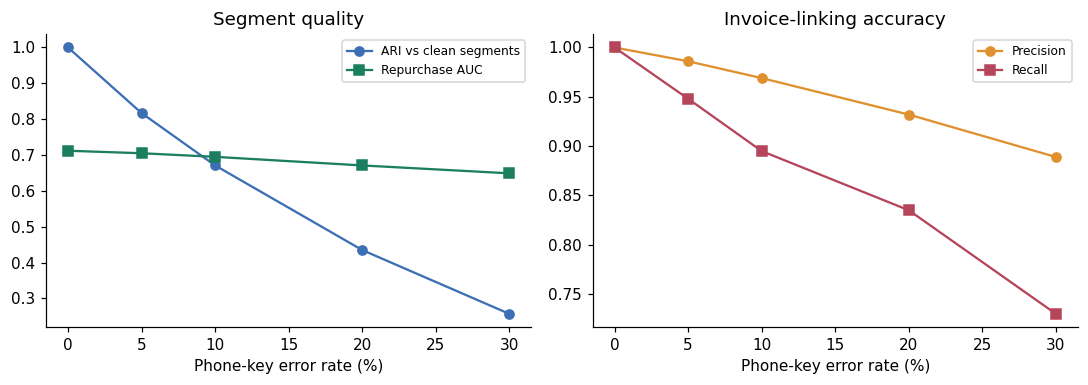

,Error rate (%),Entities,Link precision,Link recall,Repurchase AUC,ARI vs clean
0,0,3317,1.000,1.000,0.712,1.000
1,5,3400,0.986,0.948,0.705,0.817
2,10,3483,0.969,0.895,0.695,0.671
3,20,3649,0.932,0.835,0.671,0.435
4,30,3815,0.889,0.730,0.649,0.257


In [20]:
def pairs(counts):
    n = np.asarray(counts, float)
    return (n * (n - 1) / 2).sum()


def simulate(e, seed):
    rng = np.random.default_rng(seed)
    inv = pre[["InvoiceNo", "CustomerID"]].drop_duplicates().reset_index(drop=True)
    cust = fpre.index.values
    key = {c: f"{c:06d}" for c in cust}
    nm = int(round(e * len(cust)))
    perm = rng.permutation(cust)
    for a, b in perm[: nm - nm % 2].reshape(-1, 2):
        key[b] = key[a]                                   # two customers share one phone
    n_inv = inv["CustomerID"].value_counts()
    split = [c for c in perm[nm:] if n_inv[c] >= 2][:nm]  # one customer uses two phones
    inv["entity"] = inv["CustomerID"].map(key)
    if split:
        r = inv[inv["CustomerID"].isin(split)].copy()
        r["r"] = rng.random(len(r))
        r = r.sort_values(["CustomerID", "r"])
        second = r.groupby("CustomerID").cumcount() < r.groupby("CustomerID")["r"].transform("size") // 2
        idx = second[second].index
        inv.loc[idx, "entity"] = inv.loc[idx, "entity"] + "b"
    t = pre.merge(inv[["InvoiceNo", "entity"]], on="InvoiceNo").drop(columns="CustomerID").rename(columns={"entity": "CustomerID"})
    fe = build_features(t, CUTOFF)
    elab = pd.Series(km_labels(fe, 4), index=fe.index)
    # Each true customer takes the segment of the entity holding most of their invoices.
    owner = (inv.groupby(["CustomerID", "entity"]).size().reset_index(name="n")
             .sort_values("n").drop_duplicates("CustomerID", keep="last").set_index("CustomerID")["entity"])
    clab = elab.reindex(owner.reindex(cust).values).values
    tp = pairs(inv.groupby(["entity", "CustomerID"]).size().values)
    return dict(entities=len(fe), precision=tp / pairs(inv["entity"].value_counts().values),
                recall=tp / pairs(inv["CustomerID"].value_counts().values),
                auc=evaluate(clab, y, spend)[0]["auc"], ari=adjusted_rand_score(lab_pre, clab))


sim_rows = []
for e in (0.0, 0.05, 0.10, 0.20, 0.30):
    runs = pd.DataFrame([simulate(e, SEED + r) for r in range(5)]).mean()
    sim_rows.append({"Error rate (%)": int(e * 100), "Entities": int(round(runs["entities"])), "Link precision": round(runs["precision"], 3),
                     "Link recall": round(runs["recall"], 3), "Repurchase AUC": round(runs["auc"], 3), "ARI vs clean": round(runs["ari"], 3)})
sim_tbl = save_table(pd.DataFrame(sim_rows), "t_guest_sim")
assert sim_tbl.loc[0, "ARI vs clean"] == 1.0, "zero-error run must reproduce the clean segments"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(sim_tbl["Error rate (%)"], sim_tbl["ARI vs clean"], "o-", color="#3c6fb4", label="ARI vs clean segments")
axes[0].plot(sim_tbl["Error rate (%)"], sim_tbl["Repurchase AUC"], "s-", color="#1b7f5f", label="Repurchase AUC")
axes[0].set_xlabel("Phone-key error rate (%)"); axes[0].legend(fontsize=8); axes[0].set_title("Segment quality")
axes[1].plot(sim_tbl["Error rate (%)"], sim_tbl["Link precision"], "o-", color="#e0912f", label="Precision")
axes[1].plot(sim_tbl["Error rate (%)"], sim_tbl["Link recall"], "s-", color="#b5455b", label="Recall")
axes[1].set_xlabel("Phone-key error rate (%)"); axes[1].legend(fontsize=8); axes[1].set_title("Invoice-linking accuracy")
savefig("f_guest_sim")
sim_tbl

## Part 12 — Marketing queue
One message pair per customer. **Nothing is sent**: a real deployment needs consent and an opt-out.

In [21]:
# Two-track queue (Part 4b): established customers get value-based offers, early-stage customers get lifecycle messages.
TRACK_SHORT = SHORT + ["Promising New", "Developing New", "One-and-Done"]
seg_id = seg2.map({s: i for i, s in enumerate(TRACK_NAMES)}).values
STRATEGY = pd.DataFrame({
    "Segment": TRACK_SHORT, "Track": ["Established"] * 4 + ["Early-stage"] * 3,
    "Customers": [int((seg_id == i).sum()) for i in range(7)],
    "Goal": ["Retain and reward", "Grow value", "Win over before they lapse", "Reactivate cheaply",
             "Turn into regulars", "Welcome; get the second order", "Win a second order"],
    "Message approach": ["Thank by name; early access; no discount", "New arrivals; 15% bundle offer",
                         "Recognise last order; 20% reorder incentive", "We miss you; 10% voucher",
                         "Thank; suggest related items", "Welcome; review request; free delivery on 2nd order",
                         "Reminder of first order; 10% second-order code"]})
save_table(STRATEGY, "t_strategy")
EMAIL = ["Hi {id}, thank you for spending £{m:,.2f} across {d} items! VIP early access unlocked.",
         "Hi {id}, we curated new arrivals for your {d}-item basket! Use code LOYAL15.",
         "Hi {id}, loved your last order (£{m:,.2f})! Come back with code WELCOME20.",
         "Hi {id}, we miss you! Enjoy a 10% reactivation voucher: COMEBACK10.",
         "Hi {id}, thanks for your first orders! Here are items that go well with your {d}-item basket.",
         "Hi {id}, welcome! Tell us how your order went - your second order ships free.",
         "Hi {id}, it has been a while since your first order. Here is 10% off your second: SECOND10."]
WA = ["Hello {id}, your priority VIP reward is ready!", "Hi {id}, claim 15% off your next bundle order!",
      "Hello {id}, reorder today and save 20%!", "Hi {id}, we miss you - 10% off is waiting for you.",
      "Hi {id}, thanks for shopping with us! New picks for you are ready.",
      "Welcome {id}! How was your order? Your next one ships free.",
      "Hi {id}, your 10% second-order code SECOND10 is waiting."]
q = feat.reset_index()
q["Segment"], q["Segment_ID"] = seg2.values, seg_id
q["Email"] = [EMAIL[s].format(id=f"ID-{c}", m=m, d=d) for c, m, d, s in zip(q["CustomerID"], q["Monetary"], q["Basket_Depth"], seg_id)]
q["WhatsApp"] = [WA[s].format(id=f"ID-{c}") for c, s in zip(q["CustomerID"], seg_id)]
q = q.sort_values(["Segment_ID", "Monetary"], ascending=[True, False])
q.drop(columns="Segment_ID").to_csv(TAB / "marketing_queue_4338.csv", index=False)
examples = q.groupby("Segment_ID").head(1)[["Segment", "CustomerID", "WhatsApp"]]
save_table(examples, "t_queue_examples")
q.groupby("Segment_ID").head(1)[["Segment", "CustomerID", "Email", "WhatsApp"]]

,Segment,CustomerID,Email,WhatsApp
1689,Champions (VIP Loyalists),14646,"Hi ID-14646, thank you for spending £280,206.0...","Hello ID-14646, your priority VIP reward is re..."
330,Loyal & Promising Regulars,12753,"Hi ID-12753, we curated new arrivals for your ...","Hi ID-12753, claim 15% off your next bundle or..."
3687,High-Potential / At-Risk,17396,"Hi ID-17396, loved your last order (£7,330.80)...","Hello ID-17396, reorder today and save 20%!"
2502,Hibernating / Lost,15749,"Hi ID-15749, we miss you! Enjoy a 10% reactiva...","Hi ID-15749, we miss you - 10% off is waiting ..."
3008,Promising Newcomers,16446,"Hi ID-16446, thanks for your first orders! Her...","Hi ID-16446, thanks for shopping with us! New ..."
2087,Developing Newcomers,15195,"Hi ID-15195, welcome! Tell us how your order w...",Welcome ID-15195! How was your order? Your nex...
597,One-and-Done Risk,13135,"Hi ID-13135, it has been a while since your fi...","Hi ID-13135, your 10% second-order code SECOND..."


## Part 13 — New: full Python pipeline on the Kaggle Daraz BD / Pickaboo file
Same cleaning, identity key (phone number), features and K-Means as above. This file has only 25 customers,
so it is a **practical test of portability**, not evidence of accuracy.

In [22]:
dz = pd.read_csv(DATA / "daraz_pickaboo_orders.csv", dtype={"whatsapp_phone": str})
dz["created_at"] = pd.to_datetime(dz["created_at"])
dz_valid = dz[(dz["quantity"] > 0) & (dz["total_price"] > 0)]
dz_t = pd.DataFrame({"CustomerID": dz_valid["whatsapp_phone"].str[-10:], "InvoiceNo": dz_valid["order_id"], "InvoiceDate": dz_valid["created_at"],
                     "StockCode": dz_valid["sku"], "Amount": dz_valid["total_price"]})
dz_f = build_features(dz_t, dz_t["InvoiceDate"].max() + pd.Timedelta(days=1))
dz_X = scale(dz_f)
dz_lab = rank_by_spend(kmeans(4).fit_predict(dz_X), dz_f)
dz_sum = pd.DataFrame({"Item": ["Order lines", "Valid order lines", "Unique customers (phone key)", "Rows with a customer ID",
                                "Total order value (Tk)", "Silhouette (k=4)", "Davies-Bouldin (k=4)", "Hopkins"],
                       "Value": [len(dz), len(dz_valid), dz_f.shape[0], int(dz["user_id"].notna().sum()), round(float(dz["total_price"].sum()), 0),
                                 round(silhouette_score(dz_X, dz_lab), 3), round(davies_bouldin_score(dz_X, dz_lab), 3), round(hopkins(dz_X, frac=0.4), 3)]})
save_table(dz_sum, "t_daraz_summary")
dz_prof = dz_f.groupby(dz_lab).mean().round(1)
dz_prof.insert(0, "Customers", pd.Series(dz_lab).value_counts().sort_index().values)
dz_prof.index = [SHORT[i] for i in dz_prof.index]
save_table(dz_prof.rename_axis("Segment").rename(columns={"InterPurchase_Time": "T", "Basket_Depth": "D"}), "t_daraz_segments", index=True)
dz_ch = dz.groupby(["channel", "status"]).agg(Orders=("order_id", "size"), Value=("total_price", "sum")).reset_index()
save_table(dz_ch.rename(columns={"channel": "Channel", "status": "Status", "Value": "Value (Tk)"}), "t_daraz_channels")
RESULTS["daraz_silhouette"] = float(dz_sum.iloc[5, 1])
RESULTS["daraz_customers"] = int(dz_f.shape[0])
dz_sum

,Item,Value
0,Order lines,1049.000
1,Valid order lines,1049.000
2,Unique customers (phone key),25.000
3,Rows with a customer ID,545.000
4,Total order value (Tk),1146311.000
5,Silhouette (k=4),0.317
6,Davies-Bouldin (k=4),0.812
7,Hopkins,0.736


## Part 14 — New: early-stage customer segmentation (supervisor's question)
*Is segmentation reliable for new customers or customers with little purchase history, and how well does it
predict their future behaviour?*

**Early-stage** at the cutoff = first purchase within the previous 90 days **or** at most 2 orders.
14a size and value · 14b reliability (stability, label persistence) · 14c effectiveness (out-of-sample, within the group)
· 14d cold-start curve (by order count, and by length of observed history on a fixed cohort).

In [23]:
first_buy = pre.groupby("CustomerID")["InvoiceDate"].min().reindex(fpre.index)
tenure = (CUTOFF - first_buy).dt.days.values
early = (tenure <= 90) | (fpre["Frequency"].values <= 2)
est = ~early
pre_rev = fpre["Monetary"].values
ov = pd.DataFrame({
    "Group": ["Early-stage", "  new (first order <= 90 days)", "  low history (<= 2 orders)", "Established", "All"],
    "Customers": [early.sum(), (tenure <= 90).sum(), (fpre["Frequency"].values <= 2).sum(), est.sum(), len(fpre)],
    "Share (%)": [round(100 * m.mean(), 1) for m in (early, tenure <= 90, fpre["Frequency"].values <= 2, est, np.ones_like(early))],
    "Revenue before cutoff (%)": [round(100 * pre_rev[m].sum() / pre_rev.sum(), 1) for m in (early, tenure <= 90, fpre["Frequency"].values <= 2, est, np.ones_like(early))],
    "Bought again after cutoff (%)": [round(100 * y[m].mean(), 1) for m in (early, tenure <= 90, fpre["Frequency"].values <= 2, est, np.ones_like(early))],
})
save_table(ov, "t_early_overview")
RESULTS["early_n"], RESULTS["early_pct"] = int(early.sum()), round(100 * early.mean(), 1)
RESULTS["early_repurchase_pct"], RESULTS["est_repurchase_pct"] = round(100 * y[early].mean(), 1), round(100 * y[est].mean(), 1)
ov

,Group,Customers,Share (%),Revenue before cutoff (%),Bought again after cutoff (%)
0,Early-stage,2065,62.3,20.9,45.6
1,new (first order <= 90 days),592,17.8,6.3,51.9
2,low history (<= 2 orders),2027,61.1,19.3,45.0
3,Established,1252,37.7,79.1,80.7
4,All,3317,100.0,100.0,58.8


In [24]:
# 14b — a dedicated early-stage model. T is almost always 0 for these customers, so Tenure (days since first order) replaces it.
fe_early = fpre[early].assign(Tenure=tenure[early])
Xe = scale(fe_early, EARLY_FEATS)
ek_rows = []
for k in range(2, 7):
    lb = kmeans(k).fit_predict(Xe)
    ek_rows.append({"k": k, "Silhouette": round(silhouette_score(Xe, lb), 4), "DBI": round(davies_bouldin_score(Xe, lb), 4),
                    "Mean bootstrap ARI": round(bootstrap_ari(Xe, k).mean(), 4)})
ek_tbl = save_table(pd.DataFrame(ek_rows), "t_early_k")

X_est = scale(fpre[est])
RESULTS["est_k4_stability"] = round(bootstrap_ari(X_est, 4).mean(), 4)
RESULTS["est_k4_silhouette"] = round(silhouette_score(X_est, kmeans(4).fit_predict(X_est)), 4)
RESULTS["early_k3_stability"] = float(ek_tbl.loc[ek_tbl["k"] == 3, "Mean bootstrap ARI"].iloc[0])
RESULTS["early_k3_silhouette"] = float(ek_tbl.loc[ek_tbl["k"] == 3, "Silhouette"].iloc[0])

early_lab = rank_by_spend(kmeans(3).fit_predict(Xe), fe_early)
ep = fe_early.groupby(early_lab)[EARLY_FEATS].mean().round(1)
ep.insert(0, "Customers", pd.Series(early_lab).value_counts().sort_index().values)
ep["Bought again (%)"] = pd.Series(y[early]).groupby(early_lab).mean().mul(100).round(1).values
ep["Future spend per customer"] = pd.Series(spend[early]).groupby(early_lab).mean().round(0).values
ep.index = EARLY_NAMES
save_table(ep.rename_axis("Early-stage segment"), "t_early_profiles", index=True)

# Label persistence: does the segment given at the cutoff still hold when the full history is known?
full_lab = pd.Series(lab, index=feat.index).reindex(fpre.index).values
persist = pd.DataFrame({"Group": ["Early-stage", "Established"],
                        "Same segment at end of data (%)": [round(100 * (lab_pre[m] == full_lab[m]).mean(), 1) for m in (early, est)],
                        "ARI (cutoff vs end)": [round(adjusted_rand_score(lab_pre[m], full_lab[m]), 4) for m in (early, est)],
                        "Bootstrap ARI": [RESULTS["early_k3_stability"], RESULTS["est_k4_stability"]],
                        "Silhouette": [RESULTS["early_k3_silhouette"], RESULTS["est_k4_silhouette"]]})
save_table(persist, "t_early_reliability")
ek_tbl, ep, persist

(   k  Silhouette     DBI  Mean bootstrap ARI
 0  2      0.3032  1.4527              0.8682
 1  3      0.3544  1.0733              0.9740
 2  4      0.2846  1.1133              0.9556
 3  5      0.2869  1.2518              0.9210
 4  6      0.2836  1.1833              0.8746,
                       Customers  Recency  Frequency  Monetary  Basket_Depth  \
 Promising Newcomers         653     87.3        2.0     998.0          42.4   
 Developing Newcomers        309     26.3        1.1     420.3          25.7   
 One-and-Done Risk          1103    165.7        1.0     284.1          17.3   
 
                       Tenure  Bought again (%)  Future spend per customer  
 Promising Newcomers    169.0              56.7                      441.0  
 Developing Newcomers    29.2              51.8                      510.0  
 One-and-Done Risk      167.4              37.4                      364.0  ,
          Group  Same segment at end of data (%)  ARI (cutoff vs end)  \
 0  Early-stage    

In [25]:
# 14c — effectiveness inside the early-stage group (out of sample, same protocol as Part 7).
ye, se = y[early], spend[early]
q_all = quintile_rfm(fpre)
early_methods = {
    "No segmentation": np.zeros(early.sum(), int),
    "Single guest rule (F=1 vs F>1)": (fe_early["Frequency"] > 1).astype(int).values,
    "Classic quintile RFM score": q_all[early],
    "Global K-Means k=4 label": lab_pre[early],
    "Early-stage K-Means (k=3)": early_lab,
    "Early-stage K-Means (k=4)": rank_by_spend(kmeans(4).fit_predict(Xe), fe_early),
}
eo, e_oof = [], {}
for name, lb in early_methods.items():
    m, e_oof[name] = evaluate(lb, ye, se)
    eo.append({"Method": name, "Segments": len(set(lb)), "Repurchase AUC": round(m["auc"], 3), "Spend Spearman": round(m["rho"], 3), "Adj. R2": round(m["adj_r2"], 3)})
e_sup = cross_val_predict(LogisticRegression(max_iter=2000), Xe, ye, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
eo.append({"Method": "Supervised reference (5 features)", "Segments": "–", "Repurchase AUC": round(roc_auc_score(ye, e_sup), 3), "Spend Spearman": "–", "Adj. R2": "–"})
eo_tbl = save_table(pd.DataFrame(eo), "t_early_effect")
RESULTS["est_global_auc"] = round(evaluate(lab_pre[est], y[est], spend[est])[0]["auc"], 3)


def boot_diff_arr(pa, pb, yy, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    d = np.array([roc_auc_score(yy[i], pa[i]) - roc_auc_score(yy[i], pb[i]) for i in (rng.integers(0, len(yy), len(yy)) for _ in range(B))])
    return round(d.mean(), 3), round(np.percentile(d, 2.5), 3), round(np.percentile(d, 97.5), 3)


eci = save_table(pd.DataFrame([
    dict(zip(["Comparison", "Mean", "95% CI low", "95% CI high"], (lbl, *boot_diff_arr(e_oof[a], e_oof[b], ye))))
    for lbl, a, b in [("Early K-Means k=3 minus global k=4 label", "Early-stage K-Means (k=3)", "Global K-Means k=4 label"),
                      ("Early K-Means k=3 minus guest rule", "Early-stage K-Means (k=3)", "Single guest rule (F=1 vs F>1)"),
                      ("Early K-Means k=3 minus quintile RFM", "Early-stage K-Means (k=3)", "Classic quintile RFM score")]]), "t_early_ci")
eo_tbl, eci

(                              Method Segments  Repurchase AUC Spend Spearman  \
 0                    No segmentation        1           0.499         -0.031   
 1     Single guest rule (F=1 vs F>1)        2           0.569          0.121   
 2         Classic quintile RFM score        4           0.594          0.188   
 3           Global K-Means k=4 label        4           0.599            0.2   
 4          Early-stage K-Means (k=3)        3           0.585          0.166   
 5          Early-stage K-Means (k=4)        4           0.601            0.2   
 6  Supervised reference (5 features)        –           0.628              –   
 
   Adj. R2  
 0     0.0  
 1   0.027  
 2   0.047  
 3    0.05  
 4   0.038  
 5   0.044  
 6       –  ,
                                  Comparison   Mean  95% CI low  95% CI high
 0  Early K-Means k=3 minus global k=4 label -0.015      -0.034        0.006
 1        Early K-Means k=3 minus guest rule  0.015      -0.003        0.033
 2      Early 

In [26]:
# 14d (i) — how well does the segmentation rank customers inside each history stratum?
p_glob = oof["KM Extended RFM (k=4)"]
F = fpre["Frequency"].values
strata = [("1 order", F == 1), ("2 orders", F == 2), ("3-4 orders", (F >= 3) & (F <= 4)), ("5+ orders", F >= 5)]
st_rows = []
for name, m in strata:
    auc_m = roc_auc_score(y[m], p_glob[m]) if len(set(y[m])) > 1 and len(set(p_glob[m].round(6))) > 1 else np.nan
    auc_sup = roc_auc_score(y[m], sup_p[m]) if len(set(y[m])) > 1 else np.nan
    st_rows.append({"History": name, "Customers": int(m.sum()), "Bought again (%)": round(100 * y[m].mean(), 1),
                    "Segments present": len(set(lab_pre[m])), "AUC within stratum (segments)": round(auc_m, 3), "AUC within stratum (supervised)": round(auc_sup, 3)})
st_tbl = save_table(pd.DataFrame(st_rows), "t_early_strata")
st_tbl

,History,Customers,Bought again (%),Segments present,AUC within stratum (segments),AUC within stratum (supervised)
0,1 order,1376,40.0,3,0.537,0.575
1,2 orders,651,55.6,4,0.568,0.604
2,3-4 orders,642,70.1,4,0.491,0.600
3,5+ orders,648,90.9,2,0.581,0.705


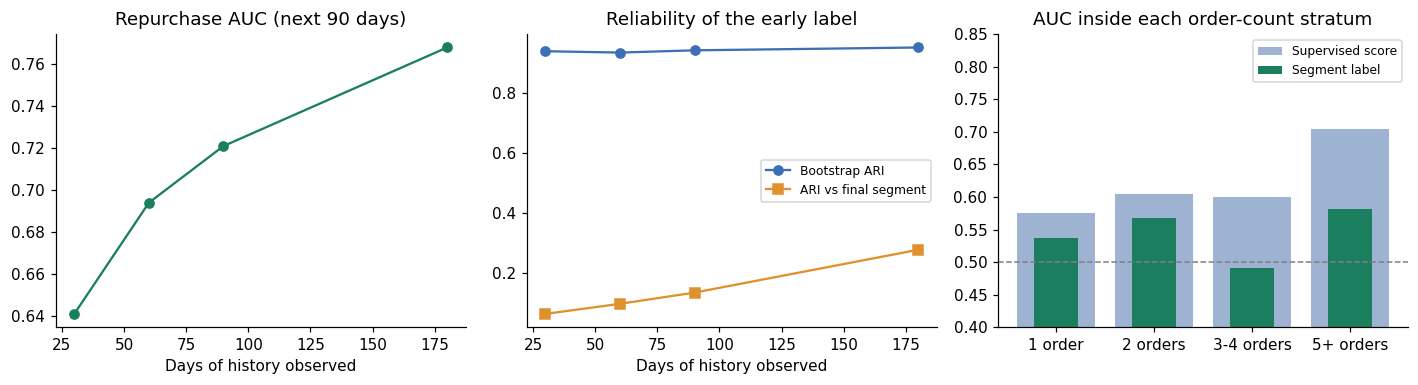

,History window (days),Cohort,Mean orders in window,Repurchase next 90 days (%),Repurchase AUC,Spend Spearman,Bootstrap ARI,ARI vs final segment
0,30,1875,1.43,55.9,0.641,0.309,0.9412,0.0627
1,60,1875,1.86,57.2,0.694,0.417,0.9367,0.0964
2,90,1875,2.30,56.2,0.721,0.468,0.9442,0.1339
3,180,1875,3.73,56.5,0.768,0.551,0.9537,0.2771


In [27]:
# 14d (ii) — history-window experiment on ONE fixed cohort: build segments from each customer's first W days only,
# predict whether they buy in the 90 days after the window, and compare with their final full-history segment.
END = tx["InvoiceDate"].max()
first_all = tx.groupby("CustomerID")["InvoiceDate"].min()
cohort = first_all[first_all <= END - pd.Timedelta(days=180 + 90)].index
txc = tx[tx["CustomerID"].isin(cohort)].merge(first_all.rename("first"), left_on="CustomerID", right_index=True)
full_cohort_lab = pd.Series(lab, index=feat.index).reindex(cohort).values
hw_rows = []
for W in (30, 60, 90, 180):
    age = (txc["InvoiceDate"] - txc["first"]).dt.days
    win = txc[age < W].copy()
    # each customer has their own reference date (first order + W days)
    win["InvoiceDate"] = win["InvoiceDate"] - (win["first"] - pd.Timestamp("2000-01-01"))
    fw = build_features(win, pd.Timestamp("2000-01-01") + pd.Timedelta(days=W)).reindex(cohort)
    out = txc[(age >= W) & (age < W + 90)].groupby("CustomerID")["Amount"].sum().reindex(cohort).fillna(0)
    yw, sw = (out > 0).astype(int).values, out.values
    lw = km_labels(fw, 4)
    m, _ = evaluate(lw, yw, sw)
    hw_rows.append({"History window (days)": W, "Cohort": len(cohort), "Mean orders in window": round(fw["Frequency"].mean(), 2),
                    "Repurchase next 90 days (%)": round(100 * yw.mean(), 1), "Repurchase AUC": round(m["auc"], 3),
                    "Spend Spearman": round(m["rho"], 3), "Bootstrap ARI": round(bootstrap_ari(scale(fw), 4).mean(), 4),
                    "ARI vs final segment": round(adjusted_rand_score(full_cohort_lab, lw), 4)})
hw_tbl = save_table(pd.DataFrame(hw_rows), "t_history_window")
RESULTS["history_window"] = hw_tbl.to_dict(orient="records")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(hw_tbl["History window (days)"], hw_tbl["Repurchase AUC"], "o-", color="#1b7f5f"); axes[0].set_title("Repurchase AUC (next 90 days)")
axes[1].plot(hw_tbl["History window (days)"], hw_tbl["Bootstrap ARI"], "o-", color="#3c6fb4", label="Bootstrap ARI")
axes[1].plot(hw_tbl["History window (days)"], hw_tbl["ARI vs final segment"], "s-", color="#e0912f", label="ARI vs final segment")
axes[1].legend(fontsize=8); axes[1].set_title("Reliability of the early label")
axes[2].bar(st_tbl["History"], st_tbl["AUC within stratum (supervised)"], color="#9db3d1", label="Supervised score")
axes[2].bar(st_tbl["History"], st_tbl["AUC within stratum (segments)"].fillna(0.5), width=0.45, color="#1b7f5f", label="Segment label")
axes[2].axhline(0.5, ls="--", color="grey", lw=1); axes[2].set_ylim(0.4, 0.85); axes[2].legend(fontsize=8); axes[2].set_title("AUC inside each order-count stratum")
for ax in axes[:2]:
    ax.set_xlabel("Days of history observed")
savefig("f_early_stage")
hw_tbl

## Part 15 — New: external validation on Olist (Brazilian marketplace, 2016–2018)
A second, more recent and very different dataset: ~100k marketplace orders where almost every customer buys once.
Same features, same K-Means, same out-of-sample protocol. Hierarchical methods are O(n²) in memory, so the
8-algorithm benchmark uses a fixed random sample of 10,000 customers for every algorithm.

In [28]:
OL = DATA / "olist"
if not (OL / "olist_orders_dataset.csv").exists():
    import kagglehub, shutil
    src = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))
    OL.mkdir(exist_ok=True)
    for f in ("olist_orders_dataset.csv", "olist_order_items_dataset.csv", "olist_customers_dataset.csv"):
        shutil.copy(src / f, OL / f)

o_orders = pd.read_csv(OL / "olist_orders_dataset.csv", parse_dates=["order_purchase_timestamp"])
o_items = pd.read_csv(OL / "olist_order_items_dataset.csv")
o_cust = pd.read_csv(OL / "olist_customers_dataset.csv")
o_steps = [("Orders (raw)", len(o_orders))]
o_ok = o_orders[o_orders["order_status"] == "delivered"]
o_steps.append(("Delivered orders", len(o_ok)))
o_tx = (o_ok.merge(o_cust[["customer_id", "customer_unique_id"]], on="customer_id")
            .merge(o_items[["order_id", "product_id", "price"]], on="order_id"))
o_tx = o_tx[o_tx["price"] > 0]
o_steps.append(("Order lines with a priced item", len(o_tx)))
o_tx = pd.DataFrame({"CustomerID": o_tx["customer_unique_id"], "InvoiceNo": o_tx["order_id"], "InvoiceDate": o_tx["order_purchase_timestamp"],
                     "StockCode": o_tx["product_id"], "Amount": o_tx["price"]})
o_feat = build_features(o_tx, o_tx["InvoiceDate"].max() + pd.Timedelta(days=1))
o_steps.append(("Unique customers", len(o_feat)))
save_table(pd.DataFrame(o_steps, columns=["Step", "Count"]), "t_olist_cleaning")
o_X = scale(o_feat)
RESULTS["olist_customers"] = len(o_feat)
RESULTS["olist_single_pct"] = round(100 * (o_feat["Frequency"] == 1).mean(), 2)
RESULTS["olist_hopkins"] = round(hopkins(o_X), 3)
o_feat.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,93358.0,237.941773,152.591453,1.00,114.00,219.00,346.0000,714.0
Frequency,93358.0,1.033420,0.209097,1.00,1.00,1.00,1.0000,15.0
Monetary,93358.0,141.621480,215.694014,0.85,47.65,89.73,154.7375,13440.0
InterPurchase_Time,93358.0,2.457209,23.404063,0.00,0.00,0.00,0.0000,609.0
Basket_Depth,93358.0,1.068843,0.316919,1.00,1.00,1.00,1.0000,14.0


In [29]:
rng_o = np.random.default_rng(SEED)
o_sample = rng_o.choice(len(o_X), 10_000, replace=False)
Xs = o_X[o_sample]
o_k_rows = []
for k in range(2, 9):
    km = kmeans(k).fit(o_X)
    ls = km.labels_[o_sample]
    o_k_rows.append({"k": k, "WCSS": round(km.inertia_, 1), "Silhouette (10k sample)": round(silhouette_score(Xs, ls), 4),
                     "DBI": round(davies_bouldin_score(o_X, km.labels_), 4), "CH": round(calinski_harabasz_score(o_X, km.labels_), 1)})
o_k_tbl = save_table(pd.DataFrame(o_k_rows), "t_olist_k")

o_algos = {
    "K-Means": lambda: kmeans(4).fit_predict(Xs),
    "Ward": lambda: AgglomerativeClustering(4, linkage="ward").fit_predict(Xs),
    "Average linkage": lambda: AgglomerativeClustering(4, linkage="average").fit_predict(Xs),
    "Complete linkage": lambda: AgglomerativeClustering(4, linkage="complete").fit_predict(Xs),
    "Gaussian mixture": lambda: GaussianMixture(4, random_state=SEED).fit_predict(Xs),
    "DBSCAN (0.8, 10)": lambda: DBSCAN(eps=0.8, min_samples=10).fit_predict(Xs),
    "HDBSCAN (min size 50)": lambda: HDBSCAN(min_cluster_size=50).fit_predict(Xs),
    "BIRCH": lambda: Birch(n_clusters=4).fit_predict(Xs),
}
o_bench, o_km = [], None
for name, fn in o_algos.items():
    t0 = time.perf_counter(); lb = fn(); dt = time.perf_counter() - t0
    o_km = lb if name == "K-Means" else o_km
    core = lb >= 0
    nk = len(set(lb[core]))
    s = (silhouette_score(Xs[core], lb[core]), davies_bouldin_score(Xs[core], lb[core])) if nk > 1 else (np.nan, np.nan)
    noise, smin, smax, ok = validity(lb)
    o_bench.append({"Algorithm": name, "Clusters": nk, "Silhouette": round(s[0], 4), "DBI": round(s[1], 4), "Noise (%)": round(noise, 2),
                    "Largest (%)": round(smax, 2), "Valid": ok, "Time (s)": round(dt, 2), "ARI vs K-Means": round(adjusted_rand_score(o_km, lb), 4)})
o_bench_tbl = save_table(pd.DataFrame(o_bench), "t_olist_benchmark")
RESULTS["olist_stability_k4"] = round(bootstrap_ari(o_X, 4, B=10).mean(), 4)
o_lab = rank_by_spend(kmeans(4).fit_predict(o_X), o_feat)
o_prof = o_feat.groupby(o_lab)[FEATS].mean().round(2)
o_prof.insert(0, "Share (%)", (pd.Series(o_lab).value_counts(normalize=True).sort_index() * 100).round(2).values)
o_prof.insert(0, "Customers", pd.Series(o_lab).value_counts().sort_index().values)
o_prof.index = [SHORT[i] for i in o_prof.index]
save_table(o_prof.rename_axis("Segment").rename(columns={"InterPurchase_Time": "T", "Basket_Depth": "D"}), "t_olist_segments", index=True)
RESULTS["olist_silhouette_k4"] = float(o_k_tbl.loc[o_k_tbl["k"] == 4, "Silhouette (10k sample)"].iloc[0])
o_k_tbl, o_bench_tbl

(   k      WCSS  Silhouette (10k sample)     DBI       CH
 0  2  280698.9                   0.7843  0.6426  61890.9
 1  3  219641.7                   0.3745  0.9688  52523.2
 2  4  170026.5                   0.4023  0.8878  54313.3
 3  5  125129.2                   0.3814  0.8132  63724.3
 4  6  105075.4                   0.3890  0.7954  64271.6
 5  7   91307.3                   0.3455  0.8370  63982.0
 6  8   81394.5                   0.3496  0.8117  63144.0,
                Algorithm  Clusters  Silhouette     DBI  Noise (%)  \
 0                K-Means         4      0.4016  0.8916       0.00   
 1                   Ward         4      0.4369  0.8492       0.00   
 2        Average linkage         4      0.8099  0.3890       0.00   
 3       Complete linkage         4      0.6829  0.4950       0.00   
 4       Gaussian mixture         4      0.6037  0.6867       0.00   
 5       DBSCAN (0.8, 10)         5      0.5812  0.4839       1.85   
 6  HDBSCAN (min size 50)         3      0.59

In [30]:
# Out-of-sample on Olist: segments from orders before 1 Mar 2018, repurchase in the next 180 days.
O_CUT = pd.Timestamp("2018-03-01")
o_pre = o_tx[o_tx["InvoiceDate"] < O_CUT]
o_post = o_tx[(o_tx["InvoiceDate"] >= O_CUT) & (o_tx["InvoiceDate"] < O_CUT + pd.Timedelta(days=180))]
o_fp = build_features(o_pre, O_CUT)
o_sp = o_post.groupby("CustomerID")["Amount"].sum().reindex(o_fp.index).fillna(0.0).values
o_y = (o_sp > 0).astype(int)
o_methods = {
    "No segmentation": np.zeros(len(o_fp), int),
    "Single guest rule (F=1 vs F>1)": (o_fp["Frequency"] > 1).astype(int).values,
    "Classic quintile RFM score": quintile_rfm(o_fp),
    "KM Extended RFM (k=2)": km_labels(o_fp, 2),
    "KM Extended RFM (k=4)": km_labels(o_fp, 4),
    "KM plain RFM (k=4)": km_labels(o_fp, 4, RFM3),
}
o_rows, o_oof = [], {}
for name, lb in o_methods.items():
    m, o_oof[name] = evaluate(lb, o_y, o_sp)
    o_rows.append({"Method": name, "Repurchase AUC": round(m["auc"], 3), "Spend Spearman": round(m["rho"], 3)})
o_sup = cross_val_predict(LogisticRegression(max_iter=2000), scale(o_fp), o_y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
o_rows.append({"Method": "Supervised reference (5 features)", "Repurchase AUC": round(roc_auc_score(o_y, o_sup), 3), "Spend Spearman": "–"})
o_oos_tbl = save_table(pd.DataFrame(o_rows), "t_olist_oos")
o_ci = save_table(pd.DataFrame([dict(zip(["Comparison", "Mean", "95% CI low", "95% CI high"], (lbl, *boot_diff_arr(o_oof[a], o_oof[b], o_y))))
                                for lbl, a, b in [("k=4 minus k=2", "KM Extended RFM (k=4)", "KM Extended RFM (k=2)"),
                                                  ("k=4 minus guest rule", "KM Extended RFM (k=4)", "Single guest rule (F=1 vs F>1)"),
                                                  ("Extended k=4 minus plain RFM k=4", "KM Extended RFM (k=4)", "KM plain RFM (k=4)")]]), "t_olist_ci")
RESULTS["olist_oos_customers"], RESULTS["olist_repurchase_pct"] = len(o_fp), round(100 * o_y.mean(), 2)
RESULTS["olist_auc_k4"] = float(o_oos_tbl.loc[o_oos_tbl["Method"] == "KM Extended RFM (k=4)", "Repurchase AUC"].iloc[0])
o_oos_tbl, o_ci

(                              Method  Repurchase AUC Spend Spearman
 0                    No segmentation           0.499         -0.009
 1     Single guest rule (F=1 vs F>1)           0.535          0.005
 2         Classic quintile RFM score           0.531          0.011
 3              KM Extended RFM (k=2)           0.535          0.005
 4              KM Extended RFM (k=4)           0.575          0.024
 5                 KM plain RFM (k=4)           0.568          0.018
 6  Supervised reference (5 features)           0.592              –,
                          Comparison   Mean  95% CI low  95% CI high
 0                     k=4 minus k=2  0.041       0.018        0.067
 1              k=4 minus guest rule  0.041       0.018        0.068
 2  Extended k=4 minus plain RFM k=4  0.007      -0.016        0.030)

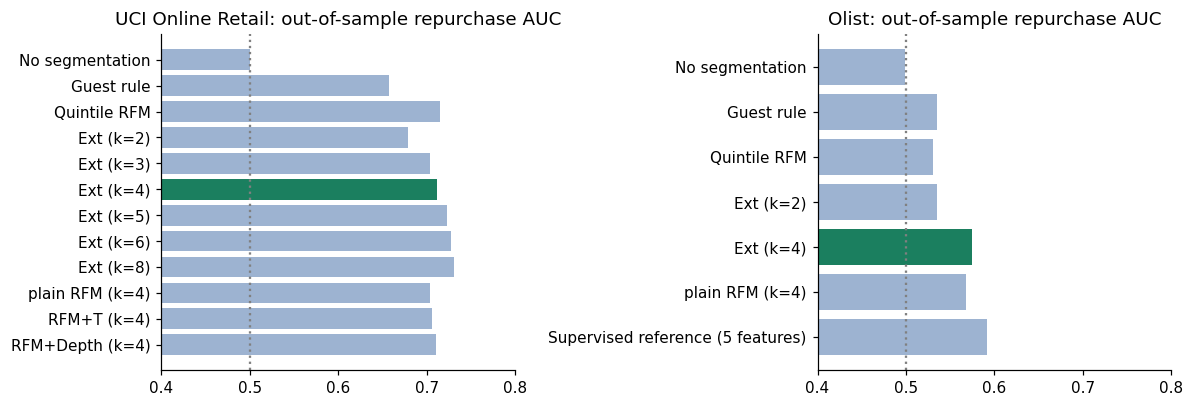

,Dataset,Customers,One-time buyers (%),Silhouette k=4,Bootstrap ARI k=4,Repurchase (%),AUC k=4,AUC guest rule
0,"UCI Online Retail (UK, 2010-11)",4338,34.42,0.3113,0.9524,58.80,0.712,0.657
1,"Olist (Brazil, 2016-18)",93358,97.00,0.4023,0.8666,1.18,0.575,0.535


In [31]:
# The two datasets side by side.
def row(name, n, single, sil, stab, auc_k4, auc_guest, rep):
    return {"Dataset": name, "Customers": n, "One-time buyers (%)": single, "Silhouette k=4": sil, "Bootstrap ARI k=4": stab,
            "Repurchase (%)": rep, "AUC k=4": auc_k4, "AUC guest rule": auc_guest}
cmp_tbl = save_table(pd.DataFrame([
    row("UCI Online Retail (UK, 2010-11)", N, RESULTS["single_pct"], RESULTS["silhouette_k4"], RESULTS["stability_k4_mean"],
        float(oos_tbl.loc[oos_tbl["Method"] == "KM Extended RFM (k=4)", "Repurchase AUC"].iloc[0]),
        float(oos_tbl.loc[oos_tbl["Method"].str.startswith("Single guest"), "Repurchase AUC"].iloc[0]), RESULTS["oos_repurchase_pct"]),
    row("Olist (Brazil, 2016-18)", RESULTS["olist_customers"], RESULTS["olist_single_pct"], RESULTS["olist_silhouette_k4"], RESULTS["olist_stability_k4"],
        RESULTS["olist_auc_k4"], float(o_oos_tbl.loc[o_oos_tbl["Method"].str.startswith("Single guest"), "Repurchase AUC"].iloc[0]), RESULTS["olist_repurchase_pct"]),
]), "t_dataset_comparison")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, tbl, title in [(axes[0], oos_tbl, "UCI Online Retail"), (axes[1], o_oos_tbl, "Olist")]:
    t = tbl[tbl["Repurchase AUC"].apply(lambda v: isinstance(v, (int, float)))]
    names = t["Method"].str.replace("KM Extended RFM", "Ext").str.replace("Classic quintile RFM score( \\(4 groups\\))?", "Quintile RFM", regex=True).str.replace("Single guest rule (F=1 vs F>1)", "Guest rule", regex=False).str.replace("KM ", "")
    ax.barh(names[::-1], t["Repurchase AUC"][::-1], color=["#1b7f5f" if n == "Ext (k=4)" else "#9db3d1" for n in names[::-1]])
    ax.axvline(0.5, ls=":", color="grey"); ax.set_xlim(0.4, 0.8); ax.set_title(f"{title}: out-of-sample repurchase AUC")
savefig("f_dataset_comparison")
cmp_tbl

## Part 16 — New: early-stage segmentation with account-creation time (TheLook eCommerce)
A third dataset that has what UCI and Olist lack: the **date each account was created**, plus profile
parameters (age, gender, country, traffic source). 100,000 users, 2019 – Jan 2024.
**Caveat:** TheLook is a *synthetic* dataset published by Google's Looker team; it tests the method,
not real customer behaviour.

At the cutoff (1 Jul 2023) every registered user is placed in one group:
**new account** (created ≤ 90 days ago) · **low history** (older account, ≤ 2 orders) · **established** ·
**registered, never bought**. Outcome: purchase in the next 180 days.

In [32]:
TL = DATA / "thelook"
if not (TL / "users.csv").exists():
    import kagglehub, shutil
    src = Path(kagglehub.dataset_download("mustafakeser4/looker-ecommerce-bigquery-dataset"))
    TL.mkdir(exist_ok=True)
    for f in ("users.csv", "order_items.csv"):
        shutil.copy(src / f, TL / f)

t_users = pd.read_csv(TL / "users.csv")
t_users["created_at"] = pd.to_datetime(t_users["created_at"], format="mixed", utc=True).dt.tz_localize(None)
t_items = pd.read_csv(TL / "order_items.csv")
t_items["created_at"] = pd.to_datetime(t_items["created_at"], format="mixed", utc=True).dt.tz_localize(None)
t_ok = t_items[t_items["status"].isin(["Complete", "Shipped", "Processing"]) & (t_items["sale_price"] > 0)]
t_tx = pd.DataFrame({"CustomerID": t_ok["user_id"], "InvoiceNo": t_ok["order_id"], "InvoiceDate": t_ok["created_at"],
                     "StockCode": t_ok["product_id"], "Amount": t_ok["sale_price"]})
save_table(pd.DataFrame([("Registered users", len(t_users)), ("Order items (raw)", len(t_items)),
                         ("Valid order items (not cancelled / returned)", len(t_ok)), ("Users with a valid order", t_ok["user_id"].nunique())],
                        columns=["Step", "Count"]), "t_tl_cleaning")

T_CUT = pd.Timestamp("2023-07-01")
t_pre = t_tx[t_tx["InvoiceDate"] < T_CUT]
t_post = t_tx[(t_tx["InvoiceDate"] >= T_CUT) & (t_tx["InvoiceDate"] < T_CUT + pd.Timedelta(days=180))]
reg = t_users[t_users["created_at"] < T_CUT].set_index("id")
acct_age = (T_CUT - reg["created_at"]).dt.days
t_fp = build_features(t_pre, T_CUT)
t_fp = t_fp[t_fp.index.isin(reg.index)]
post_spend = t_post.groupby("CustomerID")["Amount"].sum()

group = pd.Series("Established", index=reg.index)
group[~reg.index.isin(t_fp.index)] = "Registered, never bought"
low = t_fp.index[t_fp["Frequency"] <= 2]
group[group.index.isin(low)] = "Low history (<= 2 orders)"
group[(acct_age <= 90) & group.ne("Registered, never bought")] = "New account (<= 90 days)"
bought_after = reg.index.isin(post_spend.index)
t_ov = pd.DataFrame({"Users": group.value_counts(), "Share (%)": (group.value_counts(normalize=True) * 100).round(1),
                     "Bought in next 180 days (%)": (pd.Series(bought_after, index=reg.index).groupby(group).mean() * 100).round(1)})
t_ov = t_ov.reindex(["New account (<= 90 days)", "Low history (<= 2 orders)", "Established", "Registered, never bought"])
save_table(t_ov.rename_axis("Group at cutoff"), "t_tl_overview", index=True)
RESULTS["tl_users"], RESULTS["tl_buyers_pre"] = len(reg), len(t_fp)
RESULTS["tl_single_pct"] = round(100 * (t_fp["Frequency"] == 1).mean(), 1)
t_ov

,Users,Share (%),Bought in next 180 days (%)
New account (<= 90 days),678,0.8,42.0
Low history (<= 2 orders),42040,48.3,13.2
Established,2585,3.0,16.3
"Registered, never bought",41742,48.0,27.2


In [33]:
# Segmentation of buyers (same protocol as UCI / Olist).
t_X = scale(t_fp)
rng_t = np.random.default_rng(SEED)
t_sample = rng_t.choice(len(t_X), min(10_000, len(t_X)), replace=False)
t_Xs = t_X[t_sample]
t_k_rows = []
for k in range(2, 9):
    km = kmeans(k).fit(t_X)
    t_k_rows.append({"k": k, "Silhouette (10k sample)": round(silhouette_score(t_Xs, km.labels_[t_sample]), 4),
                     "DBI": round(davies_bouldin_score(t_X, km.labels_), 4), "CH": round(calinski_harabasz_score(t_X, km.labels_), 1)})
save_table(pd.DataFrame(t_k_rows), "t_tl_k")
t_bench = []
Xs = t_Xs  # the eight algorithm definitions from Part 15 (o_algos) cluster whatever Xs holds
for name, fn in o_algos.items():
    lb = fn()
    core = lb >= 0
    nk = len(set(lb[core]))
    s = silhouette_score(t_Xs[core], lb[core]) if nk > 1 else np.nan
    noise, smin, smax, ok = validity(lb)
    t_bench.append({"Algorithm": name, "Clusters": nk, "Silhouette": round(s, 4), "Noise (%)": round(noise, 2), "Largest (%)": round(smax, 2), "Valid": ok})
save_table(pd.DataFrame(t_bench), "t_tl_benchmark")
RESULTS["tl_stability_k4"] = round(bootstrap_ari(t_X, 4, B=10).mean(), 4)
t_lab = rank_by_spend(kmeans(4).fit_predict(t_X), t_fp)
RESULTS["tl_silhouette_k4"] = float(pd.DataFrame(t_k_rows).set_index("k").loc[4, "Silhouette (10k sample)"])
pd.DataFrame(t_k_rows), pd.DataFrame(t_bench)

(   k  Silhouette (10k sample)     DBI       CH
 0  2                   0.5055  0.8376  43052.2
 1  3                   0.3513  1.1599  34662.4
 2  4                   0.3559  0.9679  32031.1
 3  5                   0.3287  1.1985  29022.2
 4  6                   0.2933  1.1717  27625.0
 5  7                   0.2968  1.1057  26360.7
 6  8                   0.2958  1.1256  25188.6,
                Algorithm  Clusters  Silhouette  Noise (%)  Largest (%)  Valid
 0                K-Means         4      0.3553       0.00        37.02   True
 1                   Ward         4      0.2937       0.00        30.16   True
 2        Average linkage         4      0.4407       0.00        75.21  False
 3       Complete linkage         4      0.2118       0.00        54.23  False
 4       Gaussian mixture         4      0.3220       0.00        53.14   True
 5       DBSCAN (0.8, 10)         5      0.3069       0.73        53.44  False
 6  HDBSCAN (min size 50)         6      0.2271       5.69    

In [34]:
# Out-of-sample: do segments, and do the extra profile parameters, predict who buys in the next 180 days?
t_spend = post_spend.reindex(t_fp.index).fillna(0.0).values
t_y = (t_spend > 0).astype(int)
prof = reg.loc[t_fp.index]
P_df = pd.get_dummies(prof[["gender", "traffic_source"]].astype(str)).astype(float)
P_df["age"] = prof["age"].values
P_df["account_age"] = np.log1p(acct_age.loc[t_fp.index].values)
P_df["signup_to_first_order"] = np.log1p((t_pre.groupby("CustomerID")["InvoiceDate"].min().reindex(t_fp.index) - prof["created_at"]).dt.days.clip(lower=0).values)
P = StandardScaler().fit_transform(P_df.values)


def sup_auc(Xm, yy):
    p = cross_val_predict(LogisticRegression(max_iter=2000), Xm, yy, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return roc_auc_score(yy, p), p


t_methods = {
    "No segmentation": np.zeros(len(t_fp), int),
    "Single guest rule (F=1 vs F>1)": (t_fp["Frequency"] > 1).astype(int).values,
    "Classic quintile RFM score": quintile_rfm(t_fp),
    "KM Extended RFM (k=2)": km_labels(t_fp, 2),
    "KM Extended RFM (k=4)": t_lab,
    "KM plain RFM (k=4)": km_labels(t_fp, 4, RFM3),
}
t_rows, t_oof = [], {}
for name, lb in t_methods.items():
    m, t_oof[name] = evaluate(lb, t_y, t_spend)
    t_rows.append({"Method": name, "Repurchase AUC": round(m["auc"], 3)})
for name, Xm in [("Supervised: purchase history only", t_X), ("Supervised: history + account & profile parameters", np.hstack([t_X, P]))]:
    a, t_oof[name] = sup_auc(Xm, t_y)
    t_rows.append({"Method": name, "Repurchase AUC": round(a, 3)})
t_oos_tbl = save_table(pd.DataFrame(t_rows), "t_tl_oos")
save_table(pd.DataFrame([dict(zip(["Comparison", "Mean", "95% CI low", "95% CI high"], (lbl, *boot_diff_arr(t_oof[a], t_oof[b], t_y))))
                         for lbl, a, b in [("k=4 minus guest rule", "KM Extended RFM (k=4)", "Single guest rule (F=1 vs F>1)"),
                                           ("k=4 minus k=2", "KM Extended RFM (k=4)", "KM Extended RFM (k=2)"),
                                           ("History + profile minus history only", "Supervised: history + account & profile parameters", "Supervised: purchase history only")]]),
           "t_tl_ci")
RESULTS["tl_repurchase_pct"] = round(100 * t_y.mean(), 1)
RESULTS["tl_auc_k4"] = float(t_oos_tbl.loc[t_oos_tbl["Method"] == "KM Extended RFM (k=4)", "Repurchase AUC"].iloc[0])
t_oos_tbl

,Method,Repurchase AUC
0,No segmentation,0.500
1,Single guest rule (F=1 vs F>1),0.524
2,Classic quintile RFM score,0.561
3,KM Extended RFM (k=2),0.523
4,KM Extended RFM (k=4),0.578
5,KM plain RFM (k=4),0.573
6,Supervised: purchase history only,0.613
7,Supervised: history + account & profile parame...,0.667


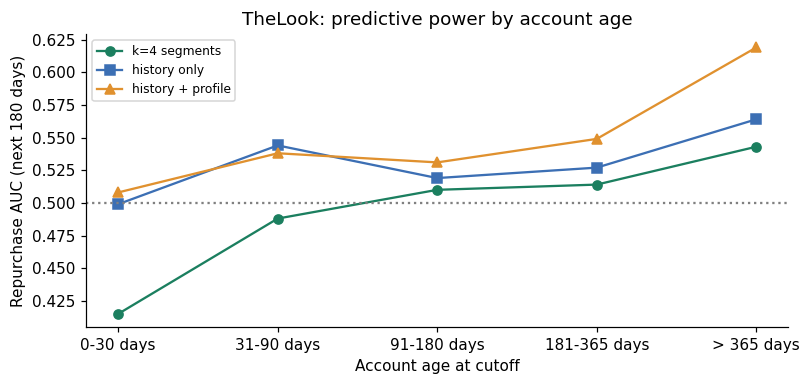

(  Account age at cutoff  Buyers  Bought again (%)  AUC: k=4 segments  \
 0             0-30 days      97              47.4              0.415   
 1            31-90 days     581              41.1              0.488   
 2           91-180 days    1554              32.5              0.510   
 3          181-365 days    4226              25.5              0.514   
 4            > 365 days   38845              11.3              0.543   
 
    AUC: history only  AUC: history + profile  
 0              0.499                   0.508  
 1              0.544                   0.538  
 2              0.519                   0.531  
 3              0.527                   0.549  
 4              0.564                   0.619  ,
        Model (new accounts only)  Silhouette  Bootstrap ARI  Repurchase AUC
 0        Early-stage K-Means k=2      0.2857         0.6871           0.510
 1        Early-stage K-Means k=3      0.2701         0.6004           0.501
 2        Early-stage K-Means k=4      0

In [35]:
# Early-stage segmentation by ACCOUNT AGE: how predictive are segments for brand-new vs old accounts?
age_band = pd.cut(acct_age.loc[t_fp.index].values, [-1, 30, 90, 180, 365, 10_000], labels=["0-30 days", "31-90 days", "91-180 days", "181-365 days", "> 365 days"])
band_rows = []
for b in age_band.categories:
    m = np.asarray(age_band == b)
    if m.sum() < 50 or len(set(t_y[m])) < 2:
        continue
    band_rows.append({"Account age at cutoff": b, "Buyers": int(m.sum()), "Bought again (%)": round(100 * t_y[m].mean(), 1),
                      "AUC: k=4 segments": round(roc_auc_score(t_y[m], t_oof["KM Extended RFM (k=4)"][m]), 3),
                      "AUC: history only": round(roc_auc_score(t_y[m], t_oof["Supervised: purchase history only"][m]), 3),
                      "AUC: history + profile": round(roc_auc_score(t_y[m], t_oof["Supervised: history + account & profile parameters"][m]), 3)})
t_band = save_table(pd.DataFrame(band_rows), "t_tl_account_age")

# A dedicated model for new accounts (<= 90 days): history + account age + signup-to-first-order delay.
new = np.asarray(acct_age.loc[t_fp.index].values <= 90)
NEW_FEATS = ["Recency", "Frequency", "Monetary", "Basket_Depth"]
f_new = t_fp[new][NEW_FEATS].assign(AccountAge=acct_age.loc[t_fp.index][new].values,
                                     SignupToFirst=np.expm1(P_df["signup_to_first_order"].values[new]))
X_new = StandardScaler().fit_transform(np.log1p(f_new))
new_rows = []
for k in (2, 3, 4):
    lb = kmeans(k).fit_predict(X_new)
    new_rows.append({"Model (new accounts only)": f"Early-stage K-Means k={k}", "Silhouette": round(silhouette_score(X_new, lb), 4),
                     "Bootstrap ARI": round(bootstrap_ari(X_new, k, B=10).mean(), 4), "Repurchase AUC": round(evaluate(lb, t_y[new], t_spend[new])[0]["auc"], 3)})
new_rows.append({"Model (new accounts only)": "Global k=4 label", "Silhouette": np.nan, "Bootstrap ARI": np.nan,
                 "Repurchase AUC": round(evaluate(t_lab[new], t_y[new], t_spend[new])[0]["auc"], 3)})
new_rows.append({"Model (new accounts only)": "Supervised: history + profile", "Silhouette": np.nan, "Bootstrap ARI": np.nan,
                 "Repurchase AUC": round(sup_auc(np.hstack([X_new, P[new]]), t_y[new])[0], 3)})
t_new = save_table(pd.DataFrame(new_rows), "t_tl_new_accounts")
RESULTS["tl_new_accounts"] = int(new.sum())

# Registered but never bought: does the profile predict a first purchase?
never = reg.index[~reg.index.isin(t_fp.index)]
pn = reg.loc[never]
Pn = pd.get_dummies(pn[["gender", "traffic_source"]].astype(str)).astype(float)
Pn["age"], Pn["account_age"] = pn["age"].values, np.log1p(acct_age.loc[never].values)
y_never = never.isin(post_spend.index).astype(int)
RESULTS["tl_never_n"], RESULTS["tl_never_convert_pct"] = len(never), round(100 * y_never.mean(), 1)
RESULTS["tl_never_profile_auc"] = round(sup_auc(StandardScaler().fit_transform(Pn.values), y_never)[0], 3)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for col, c, mk in [("AUC: k=4 segments", "#1b7f5f", "o"), ("AUC: history only", "#3c6fb4", "s"), ("AUC: history + profile", "#e0912f", "^")]:
    ax.plot(t_band["Account age at cutoff"], t_band[col], marker=mk, color=c, label=col.replace("AUC: ", ""))
ax.axhline(0.5, ls=":", color="grey"); ax.set_ylabel("Repurchase AUC (next 180 days)"); ax.set_xlabel("Account age at cutoff")
ax.set_title("TheLook: predictive power by account age"); ax.legend(fontsize=8)
savefig("f_tl_account_age")
t_band, t_new, {k: RESULTS[k] for k in ["tl_never_n", "tl_never_convert_pct", "tl_never_profile_auc"]}

## Part 17 — New: robustness test on five datasets (two more large, real datasets)
* **Online Retail II, year 1** (UCI; real; Dec 2009 – Nov 2010). Same retailer as the main dataset but the
  *earlier* year, which does not overlap the main data — an independent replication.
* **CDNOW** (real; the classic customer-base benchmark of Fader & Hardie): 23,570 customers who all made
  their first purchase in Q1 1997, followed to June 1998 — every customer starts as an early-stage customer.
  CDNOW has no product IDs, so basket depth D is constant there and drops out.

One test function runs the same protocol on every dataset: K-Means k=4 quality and stability, out-of-sample
repurchase AUC of every method, and the AUC inside the early-stage and established groups.

In [36]:
R2 = DATA / "retail2"
r2_csv = R2 / "online_retail_ii_year1.csv"
if not r2_csv.exists():
    import urllib.request, zipfile
    R2.mkdir(exist_ok=True)
    if not (R2 / "online_retail_II.xlsx").exists():
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip", R2 / "online_retail_ii.zip")
        zipfile.ZipFile(R2 / "online_retail_ii.zip").extract("online_retail_II.xlsx", R2)
    pd.read_excel(R2 / "online_retail_II.xlsx", sheet_name="Year 2009-2010", dtype={"Invoice": str, "StockCode": str}).to_csv(r2_csv, index=False)
r2_raw = pd.read_csv(r2_csv, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
r2_raw = r2_raw.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID"})
r2_tx, r2_log = clean(r2_raw)
save_table(r2_log, "t_r2_cleaning")

CD = DATA / "cdnow"
if not (CD / "CDNOW_master.txt").exists():
    import urllib.request, zipfile
    CD.mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://www.brucehardie.com/datasets/CDNOW_master.zip", CD / "CDNOW_master.zip")
    zipfile.ZipFile(CD / "CDNOW_master.zip").extract("CDNOW_master.txt", CD)
cd_raw = pd.read_csv(CD / "CDNOW_master.txt", sep=r"\s+", header=None, names=["CustomerID", "Date", "CDs", "Amount"], dtype={"CustomerID": str, "Date": str})
cd_raw = cd_raw[cd_raw["Amount"] > 0].reset_index(drop=True)
cd_tx = pd.DataFrame({"CustomerID": cd_raw["CustomerID"], "InvoiceNo": cd_raw.index.astype(str),
                      "InvoiceDate": pd.to_datetime(cd_raw["Date"], format="%Y%m%d"), "StockCode": "cd", "Amount": cd_raw["Amount"]})
print(len(r2_tx), r2_tx["CustomerID"].nunique(), len(cd_tx), cd_tx["CustomerID"].nunique())

400916 4312 69579 23502


In [37]:
def robustness_test(name, real, txd, cutoff, horizon_days):
    """The thesis protocol in one call: returns one summary row for the cross-dataset table."""
    cutoff = pd.Timestamp(cutoff)
    pre = txd[txd["InvoiceDate"] < cutoff]
    post = txd[(txd["InvoiceDate"] >= cutoff) & (txd["InvoiceDate"] < cutoff + pd.Timedelta(days=horizon_days))]
    f = build_features(pre, cutoff)
    spend_ = post.groupby("CustomerID")["Amount"].sum().reindex(f.index).fillna(0.0).values
    y_ = (spend_ > 0).astype(int)
    Xd = scale(f)
    lab4 = km_labels(f, 4)
    smp = np.random.default_rng(SEED).choice(len(Xd), min(10_000, len(Xd)), replace=False)
    first = pre.groupby("CustomerID")["InvoiceDate"].min().reindex(f.index)
    early_ = ((cutoff - first).dt.days.values <= 90) | (f["Frequency"].values <= 2)
    auc = lambda lb, m=slice(None): round(evaluate(lb[m], y_[m], spend_[m])[0]["auc"], 3)
    sup = cross_val_predict(LogisticRegression(max_iter=2000), Xd, y_, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return {
        "Dataset": name, "Real data": real, "Cutoff": str(cutoff.date()), "Horizon (days)": horizon_days,
        "Customers": len(f), "One-time (%)": round(100 * (f["Frequency"] == 1).mean(), 1), "Early-stage (%)": round(100 * early_.mean(), 1),
        "Silhouette k=4": round(silhouette_score(Xd[smp], lab4[smp]), 3), "Bootstrap ARI k=4": round(bootstrap_ari(Xd, 4, B=10).mean(), 3),
        "Valid k=4": validity(lab4)[3], "Repurchase (%)": round(100 * y_.mean(), 1),
        "AUC guest rule": auc((f["Frequency"] > 1).astype(int).values), "AUC quintile RFM": auc(quintile_rfm(f)),
        "AUC k=2": auc(km_labels(f, 2)), "AUC k=4": auc(lab4), "AUC plain RFM k=4": auc(km_labels(f, 4, RFM3)),
        "AUC supervised": round(roc_auc_score(y_, sup), 3),
        "AUC k=4 early-stage": auc(lab4, early_), "AUC k=4 established": auc(lab4, ~early_) if (~early_).sum() > 50 else np.nan,
    }


def history_curve(name, txd, windows=(30, 60, 90, 180), horizon=90):
    """Part 14d on any dataset: segments from each customer's first W days predict the next `horizon` days (fixed cohort)."""
    end = txd["InvoiceDate"].max()
    first = txd.groupby("CustomerID")["InvoiceDate"].min()
    cohort = first[first <= end - pd.Timedelta(days=max(windows) + horizon)].index
    tc = txd[txd["CustomerID"].isin(cohort)].merge(first.rename("first_buy"), left_on="CustomerID", right_index=True)
    age = (tc["InvoiceDate"] - tc["first_buy"]).dt.days
    rows = []
    for W in windows:
        win = tc[age < W].copy()
        win["InvoiceDate"] = win["InvoiceDate"] - (win["first_buy"] - pd.Timestamp("2000-01-01"))
        fw = build_features(win, pd.Timestamp("2000-01-01") + pd.Timedelta(days=W)).reindex(cohort)
        out = tc[(age >= W) & (age < W + horizon)].groupby("CustomerID")["Amount"].sum().reindex(cohort).fillna(0)
        m, _ = evaluate(km_labels(fw, 4), (out > 0).astype(int).values, out.values)
        rows.append({"Dataset": name, "History (days)": W, "Cohort": len(cohort), "Repurchase next 90 days (%)": round(100 * (out > 0).mean(), 1), "AUC k=4": round(m["auc"], 3)})
    return rows


all_rows = [
    robustness_test("UCI Online Retail (UK, 2010-11)", True, tx, "2011-09-01", 99),
    robustness_test("Online Retail II year 1 (UK, 2009-10)", True, r2_tx, "2010-07-01", 150),
    robustness_test("CDNOW (US, 1997-98)", True, cd_tx, "1997-10-01", 180),
    robustness_test("Olist (Brazil, 2016-18)", True, o_tx, "2018-03-01", 180),
    robustness_test("TheLook (synthetic, 2019-24)", False, t_tx, "2023-07-01", 180),
]
all_tbl = save_table(pd.DataFrame(all_rows), "t_all_datasets")
# Transposed copy for the thesis page (five dataset columns fit the page width; 19 measure columns do not).
save_table(all_tbl.assign(Dataset=all_tbl["Dataset"].str.replace(r" \(.*\)", "", regex=True)).set_index("Dataset").T.rename_axis("Measure"), "t_all_datasets_T", index=True)
RESULTS["all_k4_beats_guest"] = int((all_tbl["AUC k=4"] > all_tbl["AUC guest rule"]).sum())
RESULTS["all_k4_beats_k2"] = int((all_tbl["AUC k=4"] > all_tbl["AUC k=2"]).sum())
RESULTS["all_early_below_established"] = int((all_tbl["AUC k=4 early-stage"] < all_tbl["AUC k=4 established"]).sum())
RESULTS["r2_customers"], RESULTS["cd_customers"] = int(r2_tx["CustomerID"].nunique()), int(cd_tx["CustomerID"].nunique())
all_tbl.T

,0,1,2,3,4
Dataset,"UCI Online Retail (UK, 2010-11)","Online Retail II year 1 (UK, 2009-10)","CDNOW (US, 1997-98)","Olist (Brazil, 2016-18)","TheLook (synthetic, 2019-24)"
Real data,True,True,True,True,False
Cutoff,2011-09-01,2010-07-01,1997-10-01,2018-03-01,2023-07-01
Horizon (days),99,150,180,180,180
Customers,3317,2973,23500,55525,45303
One-time (%),41.5,42.9,59.1,97.1,75.0
Early-stage (%),62.3,65.5,78.2,99.8,94.3
Silhouette k=4,0.295,0.297,0.461,0.38,0.356
Bootstrap ARI k=4,0.942,0.94,0.991,0.781,0.989
Valid k=4,True,True,True,False,True


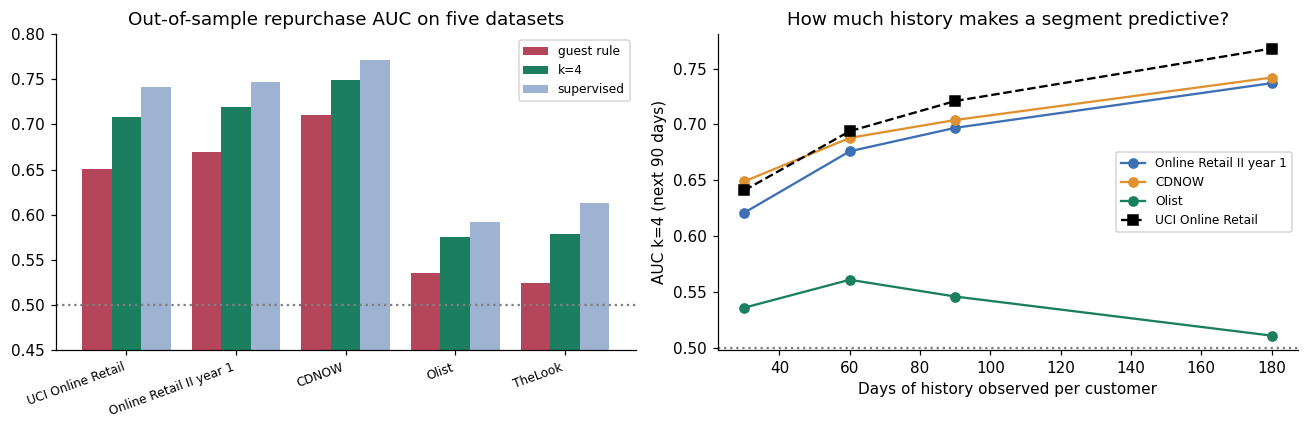

,Dataset,History (days),Cohort,Repurchase next 90 days (%),AUC k=4
0,Online Retail II year 1,30,1909,58.7,0.621
1,Online Retail II year 1,60,1909,59.8,0.676
2,Online Retail II year 1,90,1909,58.7,0.697
3,Online Retail II year 1,180,1909,56.7,0.737
4,CDNOW,30,23500,23.5,0.649
5,CDNOW,60,23500,20.7,0.688
6,CDNOW,90,23500,19.8,0.704
7,CDNOW,180,23500,17.6,0.742
8,Olist,30,37409,1.0,0.536
9,Olist,60,37409,0.8,0.561


In [38]:
hist_rows = history_curve("Online Retail II year 1", r2_tx) + history_curve("CDNOW", cd_tx) + history_curve("Olist", o_tx)
hist_tbl = save_table(pd.DataFrame(hist_rows), "t_all_history")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
short = all_tbl["Dataset"].str.replace(r" \(.*\)", "", regex=True)
xpos = np.arange(len(all_tbl))
for off, col, c in [(-0.27, "AUC guest rule", "#b5455b"), (0, "AUC k=4", "#1b7f5f"), (0.27, "AUC supervised", "#9db3d1")]:
    axes[0].bar(xpos + off, all_tbl[col], 0.27, label=col.replace("AUC ", ""), color=c)
axes[0].set_xticks(xpos, short, rotation=20, ha="right", fontsize=8); axes[0].set_ylim(0.45, 0.8); axes[0].axhline(0.5, ls=":", color="grey")
axes[0].set_title("Out-of-sample repurchase AUC on five datasets"); axes[0].legend(fontsize=8)
for (ds, g), c in zip(pd.DataFrame(hist_rows).groupby("Dataset", sort=False), ["#3c6fb4", "#e0912f", "#1b7f5f"]):
    axes[1].plot(g["History (days)"], g["AUC k=4"], "o-", color=c, label=ds)
uci_hw = pd.read_csv(TAB / "t_history_window.csv")
axes[1].plot(uci_hw["History window (days)"], uci_hw["Repurchase AUC"], "s--", color="black", label="UCI Online Retail")
axes[1].axhline(0.5, ls=":", color="grey"); axes[1].set_xlabel("Days of history observed per customer"); axes[1].set_ylabel("AUC k=4 (next 90 days)")
axes[1].set_title("How much history makes a segment predictive?"); axes[1].legend(fontsize=8)
savefig("f_all_datasets")
hist_tbl

## Save headline results
`outputs/results.json` holds every scalar quoted in the thesis text; `outputs/tables/*.tex` are included directly by the LaTeX source.

In [39]:
def to_py(o):
    if isinstance(o, dict):
        return {k: to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    return o.item() if hasattr(o, "item") else o


(THESIS / "outputs" / "results.json").write_text(json.dumps(to_py(RESULTS), indent=2), encoding="utf-8")
print(json.dumps(to_py(RESULTS), indent=2))

{
  "raw_rows": 541909,
  "clean_rows": 392692,
  "clean_share_pct": 72.46,
  "missing_id_pct": 24.93,
  "customers": 4338,
  "single_buyers": 1493,
  "single_pct": 34.42,
  "top10_revenue_pct": 61.41,
  "hopkins": 0.89,
  "monetary_skew_raw": 19.33,
  "monetary_skew_log": 0.396,
  "silhouette_k4": 0.3113,
  "segments": {
    "Champions (VIP Loyalists)": {
      "n": 515,
      "share": 11.87,
      "revenue": 59.42,
      "Recency": 12.38,
      "Frequency": 16.51,
      "Monetary": 10253.3,
      "InterPurchase_Time": 32.55,
      "Basket_Depth": 184.04
    },
    "Loyal & Promising Regulars": {
      "n": 1180,
      "share": 27.2,
      "revenue": 23.84,
      "Recency": 33.21,
      "Frequency": 4.66,
      "Monetary": 1795.53,
      "InterPurchase_Time": 73.66,
      "Basket_Depth": 87.56
    },
    "High-Potential / At-Risk": {
      "n": 1071,
      "share": 24.69,
      "revenue": 9.2,
      "Recency": 102.95,
      "Frequency": 2.68,
      "Monetary": 763.65,
      "InterPurc